# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of the second student if you are not working in a team**.

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. Riola Allegra (345795);
2. Zambrano Gabriele (339561).

Now we fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [345795,339561]  

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Shopping centres
Branded clothing
Entertainment spending
Spending on gadgets
Smoking
Alcohol
Healthy eating
History
Psychology
Mathematics
Physics
Internet
Economy Management
Biology
Reading
Foreign languages
Medicine
Art exhibitions
Religion
Countryside, outdoors
Dancing
Writing
Passive sport
Gardening
Celebrities
Science and technology
Theatre
Fun with friends
Horror
Thriller
Comedy
Sci-fi
War
Animated
Western
Dance
Country
Classical music
Pop
Rock
Metal or Hardrock
Punk
Hiphop, Rap
Reggae, Ska
Swing, Jazz
Alternative
Latino
Techno, Trance
Opera
Daily events
Prioritising workload
Thinking ahead
Final judgement
Reliability
Keeping promises
Loss of interest
Friends versus money
Funniness
Fake
Elections
Self-criticism
Empathy
Eating to survive
Giving
Compassion to animals
Borrowed stuff
Cheating in school
Changing the past
God
Dreams
Punctuality
Lying
Waiting
Mood swings
Appearence and gestures
Responding to a serious lette

,Shopping centres,Branded clothing,Entertainment spending,Spending on gadgets,Smoking,Alcohol,Healthy eating,History,Psychology,Mathematics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
260,5,5,3,4,tried smoking,social drinker,4,3,3,2,...,20,178,75,2,male,right,college/bachelor degree,no,city,block of flats
97,1,1,5,3,tried smoking,social drinker,1,4,4,3,...,19,177,64,1,female,right,primary school,no,city,block of flats
573,4,3,4,4,current smoker,social drinker,3,2,1,2,...,23,171,54,4,female,right,secondary school,no,city,block of flats
649,3,2,2,4,tried smoking,social drinker,3,3,4,3,...,19,178,88,0,female,right,secondary school,yes,city,block of flats
150,5,4,5,3,tried smoking,social drinker,5,1,3,1,...,21,176,55,1,female,right,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,5,4,2,1,tried smoking,social drinker,4,5,2,1,...,18,160,50,1,female,right,primary school,no,city,block of flats
22,4,5,3,1,former smoker,social drinker,5,5,1,1,...,20,187,80,2,male,left,secondary school,yes,village,house/bungalow
298,5,3,1,1,tried smoking,social drinker,3,1,2,1,...,18,172,60,1,female,right,primary school,no,village,house/bungalow
502,4,4,4,4,tried smoking,social drinker,4,4,3,3,...,17,182,84,1,male,right,secondary school,no,city,house/bungalow



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Shopping centres,Branded clothing,Entertainment spending,Spending on gadgets,Smoking,Alcohol,Healthy eating,History,Psychology,Mathematics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Spiders,Fear of public speaking
260,5,5,3,4,tried smoking,social drinker,4,3,3,2,...,1,4,3,few hours a day,1,2,2,2,4,3
97,1,1,5,3,tried smoking,social drinker,1,4,4,3,...,5,2,5,most of the day,1,2,2,2,2,2
573,4,3,4,4,current smoker,social drinker,3,2,1,2,...,4,4,5,few hours a day,5,2,2,4,5,3
649,3,2,2,4,tried smoking,social drinker,3,3,4,3,...,3,4,3,less than an hour a day,1,4,5,3,5,3
150,5,4,5,3,tried smoking,social drinker,5,1,3,1,...,4,4,1,few hours a day,1,2,2,5,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,5,4,2,1,tried smoking,social drinker,4,5,2,1,...,1,4,4,few hours a day,3,3,3,2,2,1
22,4,5,3,1,former smoker,social drinker,5,5,1,1,...,5,3,1,few hours a day,1,1,2,4,4,2
298,5,3,1,1,tried smoking,social drinker,3,1,2,1,...,1,3,3,less than an hour a day,3,4,3,4,5,3
502,4,4,4,4,tried smoking,social drinker,4,4,3,3,...,4,4,3,less than an hour a day,1,1,1,1,3,3



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
260,20,178,75,2,male,right,college/bachelor degree,no,city,block of flats
97,19,177,64,1,female,right,primary school,no,city,block of flats
573,23,171,54,4,female,right,secondary school,no,city,block of flats
649,19,178,88,0,female,right,secondary school,yes,city,block of flats
150,21,176,55,1,female,right,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...
229,18,160,50,1,female,right,primary school,no,city,block of flats
22,20,187,80,2,male,left,secondary school,yes,village,house/bungalow
298,18,172,60,1,female,right,primary school,no,village,house/bungalow
502,17,182,84,1,male,right,secondary school,no,city,house/bungalow


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
%matplotlib widget
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.metrics import silhouette_score,silhouette_samples
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D


## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE MinMaxScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
By the preview of the responses_ft dataset we clearly see that it includes categorical features, so we identify them with a selection of the types object in the respective column and we save them in a list and print the categorical features found.\
Since the dataset is also characterized by categorical features, encoding is necessary. In order to have an easy conversion and to avoid an increase of dimensionality we decide to use ordinal encoding (instead of one-hot encoding).\
Thanks to the class OrdinalEncoder() and its methods we map ordered categories into integers and save them into the columns of the new dataset response_ft_enc.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
The assigned scaler is the MinMaxScaler, which performs linear trasformation such that the minimum and the maximum observed values become respectively 0 and 1, and all the other values belong to the interval [0,1]. This allows to have the same numerical range for all the variables and therefore to compare them.\
Using the methods of the chosen scaler we transform the encoded dataset into a new one in a way such that later we can apply PCA algorithm avoiding 
variables with larger original scales from dominating the variance.\
After this operation we create the new encoded and preprocessed dataframe responses_ft_pp.

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [5]:
# ORDINAL ENCODING OF CATEGORICAL DATA

# select the columns of the categorical variables
categorical_cols = responses_ft.select_dtypes(include=['object', 'category']).columns.tolist()

print("Categorical features found:", categorical_cols)

# create a copy of the original dataframe
responses_ft_enc = responses_ft.copy()

# application of ordinal encoding

ord_enc = OrdinalEncoder() # class of sklearn.preprocessing useful to convert categorical variables into integer numbers
# fit_transform is a method that does in a unique step the mapping which consists of 2 steps: 
# fit: finds the distincts categories, assigns each of them to a number
# transform: applies the map to the data
responses_ft_enc[categorical_cols] = ord_enc.fit_transform(responses_ft[categorical_cols])  

print("\n*** DATASET WITH ENCODED FEATURES responses_ft_enc")
display(responses_ft_enc.head())

# MINMAX SCALING 
scaler = MinMaxScaler()
# tranform the encoded dataset using the assigned scaler
responses_ft_pp_values = scaler.fit_transform(responses_ft_enc.values)

# create the new preprocessed dataframe
responses_ft_pp = pd.DataFrame(
    responses_ft_pp_values,
    index=responses_ft_enc.index,
    columns=responses_ft_enc.columns)

print("\n*** PREPROCESSED (MINMAX-SCALED) DATASET responses_ft_pp")
display(responses_ft_pp.head())


Categorical features found: ['Smoking', 'Alcohol', 'Punctuality', 'Lying', 'Internet usage']

*** DATASET WITH ENCODED FEATURES responses_ft_enc


,Shopping centres,Branded clothing,Entertainment spending,Spending on gadgets,Smoking,Alcohol,Healthy eating,History,Psychology,Mathematics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Spiders,Fear of public speaking
260,5,5,3,4,3.0,2.0,4,3,3,2,...,1,4,3,0.0,1,2,2,2,4,3
97,1,1,5,3,3.0,2.0,1,4,4,3,...,5,2,5,2.0,1,2,2,2,2,2
573,4,3,4,4,0.0,2.0,3,2,1,2,...,4,4,5,0.0,5,2,2,4,5,3
649,3,2,2,4,3.0,2.0,3,3,4,3,...,3,4,3,1.0,1,4,5,3,5,3
150,5,4,5,3,3.0,2.0,5,1,3,1,...,4,4,1,0.0,1,2,2,5,5,1



*** PREPROCESSED (MINMAX-SCALED) DATASET responses_ft_pp


,Shopping centres,Branded clothing,Entertainment spending,Spending on gadgets,Smoking,Alcohol,Healthy eating,History,Psychology,Mathematics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Spiders,Fear of public speaking
260,1.00,1.00,0.50,0.75,1.0,1.0,0.75,0.50,0.50,0.25,...,0.00,0.75,0.5,0.0,0.0,0.25,0.25,0.25,0.75,0.50
97,0.00,0.00,1.00,0.50,1.0,1.0,0.00,0.75,0.75,0.50,...,1.00,0.25,1.0,1.0,0.0,0.25,0.25,0.25,0.25,0.25
573,0.75,0.50,0.75,0.75,0.0,1.0,0.50,0.25,0.00,0.25,...,0.75,0.75,1.0,0.0,1.0,0.25,0.25,0.75,1.00,0.50
649,0.50,0.25,0.25,0.75,1.0,1.0,0.50,0.50,0.75,0.50,...,0.50,0.75,0.5,0.5,0.0,0.75,1.00,0.50,1.00,0.50
150,1.00,0.75,1.00,0.50,1.0,1.0,1.00,0.00,0.50,0.00,...,0.75,0.75,0.0,0.0,0.0,0.25,0.25,1.00,1.00,0.00


#### Comment the results obtained after the preprocessing operation (max 100 words):
After the preprocessing operation,we have a "PCA-ready" dataset without categorical data, and coherent measurement range of values without dominant features: all the features in responses_ft_pp have numeric values and lie in the [0,1] interval. For example, for “Shopping centres” and “Branded clothing”, the lowest observed score is mapped to 0 and the highest to 1, while intermediate responses are mapped to values such as 0.25, 0.50 or 0.75.\
This shows that preferences, habits and attitudes now contribute on a comparable scale to subsequent PCA.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:


*** Comparison of variances before and after preprocessing


,variance_enc,variance_pp
Shopping centres,1.730932,0.108183
Branded clothing,1.707498,0.106719
Entertainment spending,1.356760,0.084798
Spending on gadgets,1.697382,0.106086
Smoking,1.310425,0.145603
...,...,...
Storm,1.205620,0.075351
Darkness,1.484573,0.092786
Heights,1.679364,0.104960
Spiders,2.371886,0.148243


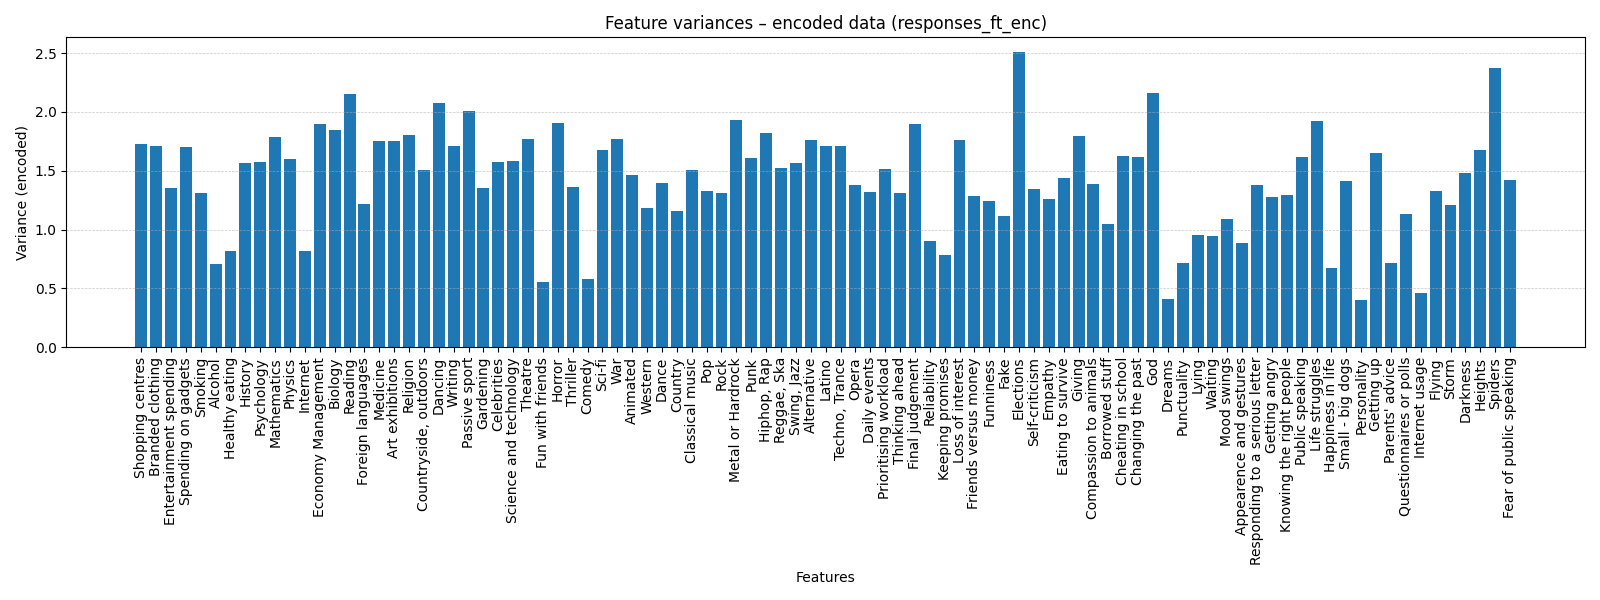

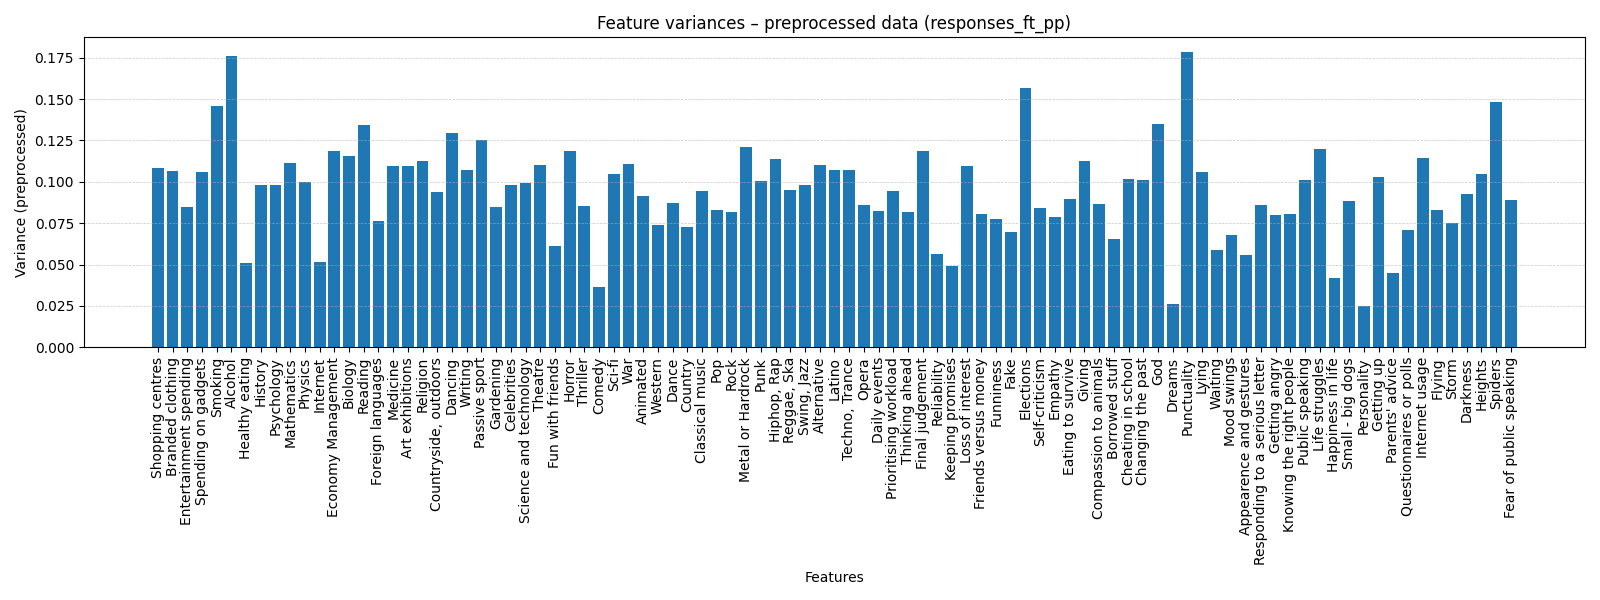

In [6]:
# FEATURE VARIANCES

# Compute variances for each feature in the two datasets
var_enc = responses_ft_enc.var(axis=0)   # encoded (non-scaled)
var_pp  = responses_ft_pp.var(axis=0)    # preprocessed (MinMax-scaled)
# create a table with variance of features of both datasets
var_comparison = pd.DataFrame({
    'variance_enc': var_enc,
    'variance_pp': var_pp})
print("\n*** Comparison of variances before and after preprocessing")
display(var_comparison)  

# visualization of variances in 2 barplots

# barplot (encoded)
plt.figure(figsize=(16, 6))
plt.bar(range(len(var_enc)), var_enc.values)
plt.xticks(
    ticks=range(len(var_enc)),
    labels=var_enc.index,
    rotation=90)
plt.xlabel('Features')
plt.ylabel('Variance (encoded)')
plt.title('Feature variances – encoded data (responses_ft_enc)')
plt.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("feature_variances_encoded.png", dpi=300, bbox_inches='tight')
plt.show()

# barplot (preprocessed)
plt.figure(figsize=(16, 6))
plt.bar(range(len(var_pp)), var_pp.values)
plt.xticks(
    ticks=range(len(var_pp)),
    labels=var_pp.index,
    rotation=90
)
plt.xlabel('Features')
plt.ylabel('Variance (preprocessed)')
plt.title('Feature variances – preprocessed data (responses_ft_pp)')
plt.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("feature_variances_preprocessed.png", dpi=300, bbox_inches='tight')
plt.show()


#### Comment the results obtained for the variances (max 150 words):
Before preprocessing, feature variances in responses_ft_enc are quite heterogeneous: some variables have large variance, others much smaller. This result is due to the fact that after encoding we still have different scales and range of values depending on unit measurement choices.

After MinMax scaling, all features are mapped to [0,1], so the absolute variances shrink and become much more comparable. The relative differences between features are still present, but there are not single variables which dominate the scale anymore.

This is exactly what we want before PCA: in the preprocessed data there aren't high-variance features that could drive the principal components, but the PCs are primarily influenced by correlation structures among variables rather than by differences in measurement scale.

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

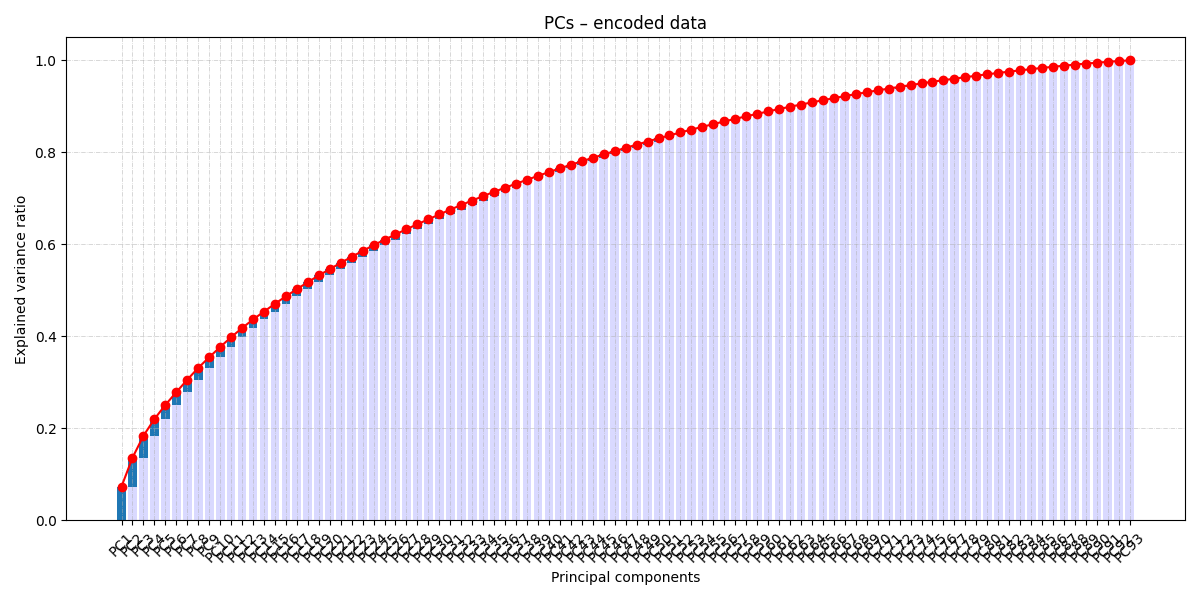

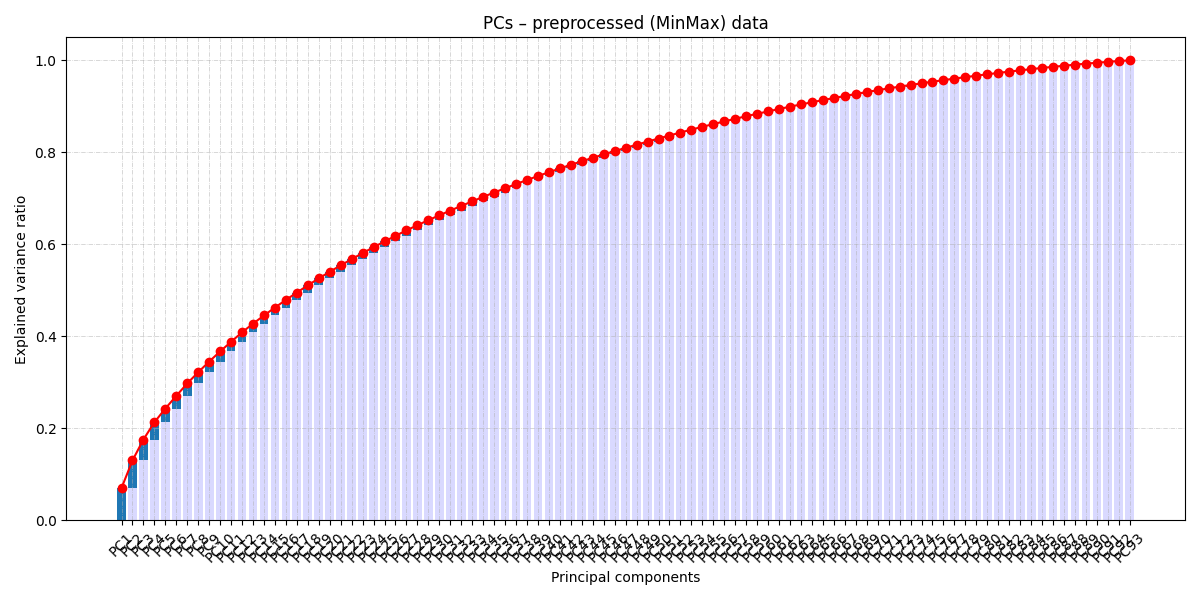

In [7]:
# PCA (ENCODED DATA)
pca_enc = PCA()                      # initialize PCA object wihout input arguments
pca_enc.fit(responses_ft_enc.values) # fit it on the data 

evr_enc = pca_enc.explained_variance_ratio_   # explained variance per PC: list of eigenvalues normalized by the sum of all of them (total variance)
cev_enc = np.cumsum(evr_enc)                  # cumulative explained variance
n_comp_enc = pca_enc.n_features_in_           # number of original features used to fit the PCA
x_enc = np.arange(n_comp_enc)                 # array of indices used as x-axis for plotting

#PLOT (ENCODED DATA)
plt.figure(figsize=(12, 6))

bottoms_enc = np.insert(cev_enc, 0, 0)[:-1]
plt.bar(x_enc, evr_enc, bottom=bottoms_enc)       
plt.bar(x_enc, bottoms_enc, color='b', alpha=0.15) 
plt.plot(x_enc, cev_enc, 'r', marker='o')          

plt.title('PCs – encoded data')
plt.xticks(x_enc, [f'PC{i}' for i in range(1, n_comp_enc + 1)], rotation=45)
plt.xlabel('Principal components')
plt.ylabel('Explained variance ratio')
plt.grid(True, linestyle='-.', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig('pca_variance_encoded.png', dpi=300, bbox_inches='tight')
plt.show()

# PCA (PREPROCESSED DATA)
pca_pp = PCA()
pca_pp.fit(responses_ft_pp.values)

evr_pp = pca_pp.explained_variance_ratio_
cev_pp = np.cumsum(evr_pp)
n_comp_pp = pca_pp.n_features_in_
x_pp = np.arange(n_comp_pp)

#PLOT (PREPROCESSED DATA)
plt.figure(figsize=(12, 6))

bottoms_pp = np.insert(cev_pp, 0, 0)[:-1]
plt.bar(x_pp, evr_pp, bottom=bottoms_pp)
plt.bar(x_pp, bottoms_pp, color='b', alpha=0.15)
plt.plot(x_pp, cev_pp, 'r', marker='o')

plt.title('PCs – preprocessed (MinMax) data')
plt.xticks(x_pp, [f'PC{i}' for i in range(1, n_comp_pp + 1)], rotation=45)
plt.xlabel('Principal components')
plt.ylabel('Explained variance ratio')
plt.grid(True, linestyle='-.', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig('pca_variance_preprocessed.png', dpi=300, bbox_inches='tight')
plt.show()


#### Comment the results obtained for the cumulative explained variances, knowing the values in the datasets and the features' variances (max 150 words):

In both datasets the cumulative explained variance grows smoothly: there isn't a small subset of PCs which is able to capture most of the variability. With 5 PCs only about a quarter of the total variance is preserved, meaning that an high-dimensional space and many components are needed to represent it well.

Comparing encoded and preprocessed data, the explained-variance curves have almost identical shape. MinMax rescaling slightly changes individual feature variances and redistributes importance among PCs, but it does not create a new dominant direction. As a result, the variance remains spread across many components, and the number of PCs needed to reach 80–90% of the total variance is large in both cases.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

m' (>=33% variance): 9
Chosen m = 5
Preserved variance with m PCs: 24.32%


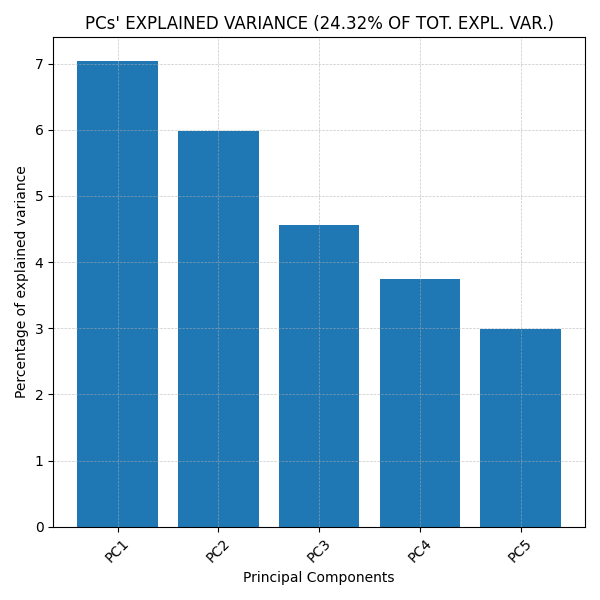


PC1 – Movies (-) vs Interests (+)
  HIGH-VALUED POSITIVE COMPONENTS:
    ['Alcohol', 'Psychology', 'Biology', 'Reading', 'Foreign languages', 'Medicine', 'Art exhibitions', 'Religion', 'Countryside, outdoors', 'Dancing', 'Writing', 'Gardening', 'Theatre', 'Classical music', 'Swing, Jazz', 'Latino', 'Opera', 'Final judgement', 'Friends versus money', 'Empathy', 'Giving', 'God', 'Life struggles', 'Storm', 'Darkness', 'Spiders']
  HIGH-VALUED NEGATIVE COMPONENTS:
    ['Spending on gadgets', 'Horror', 'Thriller', 'Sci-fi', 'War', 'Small - big dogs']


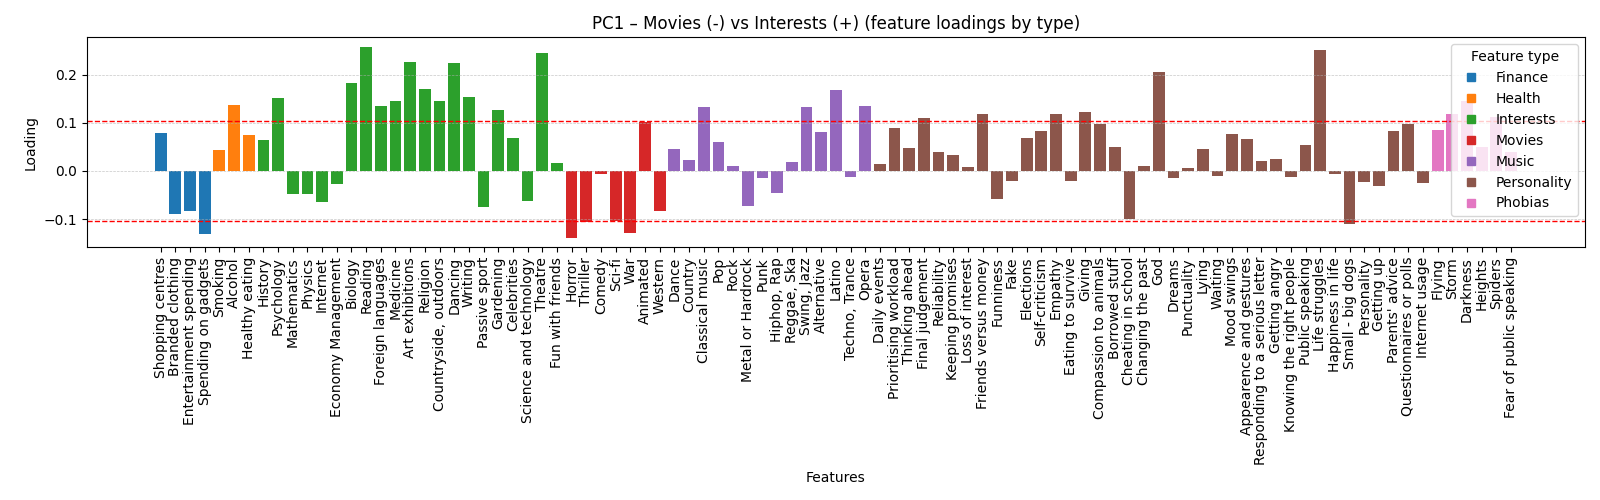


PC2 – Phobias (-) vs Music (+)
  HIGH-VALUED POSITIVE COMPONENTS:
    ['History', 'Psychology', 'Mathematics', 'Physics', 'Reading', 'Art exhibitions', 'Religion', 'Science and technology', 'Theatre', 'Sci-fi', 'War', 'Western', 'Country', 'Classical music', 'Rock', 'Metal or Hardrock', 'Punk', 'Swing, Jazz', 'Alternative', 'Opera', 'Elections']
  HIGH-VALUED NEGATIVE COMPONENTS:
    ['Shopping centres', 'Alcohol', 'Celebrities', 'Pop', 'Hiphop, Rap', 'Public speaking', 'Life struggles', 'Storm', 'Darkness', 'Spiders']


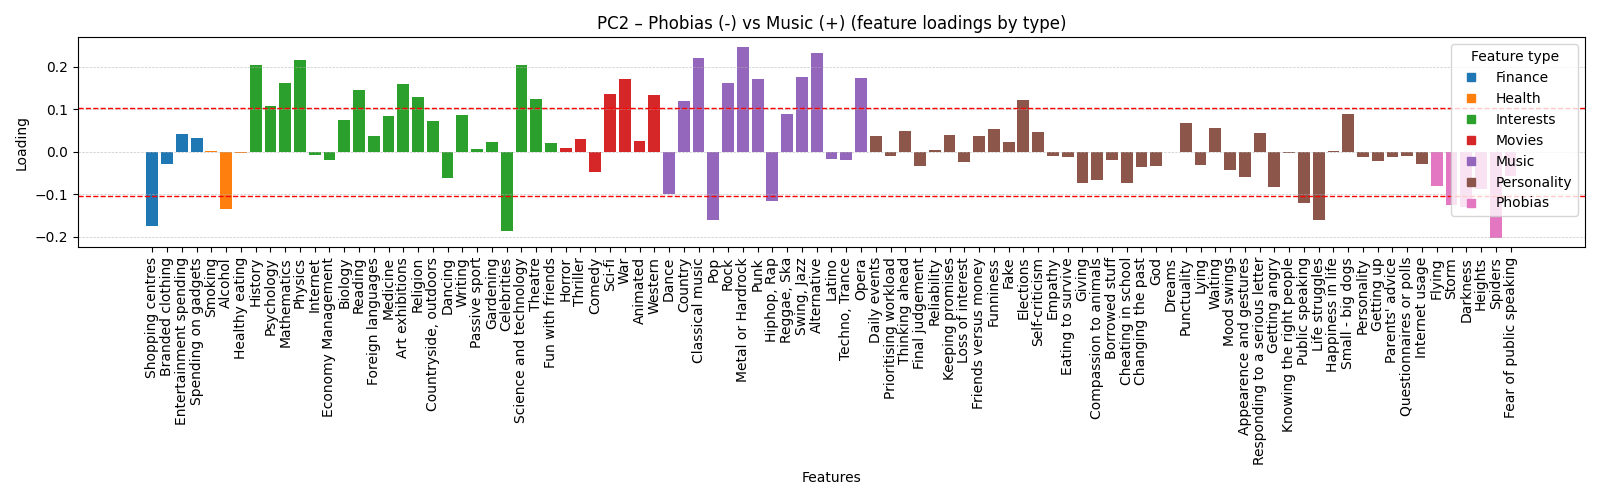


PC3 – Music (-) vs Finance (+)
  HIGH-VALUED POSITIVE COMPONENTS:
    ['Shopping centres', 'Branded clothing', 'Entertainment spending', 'Spending on gadgets', 'Economy Management', 'Dancing', 'Passive sport', 'Celebrities', 'Science and technology', 'Fun with friends', 'Horror', 'War', 'Dance', 'Pop', 'Hiphop, Rap', 'Reggae, Ska', 'Latino', 'Techno, Trance', 'Daily events', 'Loss of interest', 'Giving', 'Knowing the right people']
  HIGH-VALUED NEGATIVE COMPONENTS:
    ['Metal or Hardrock']


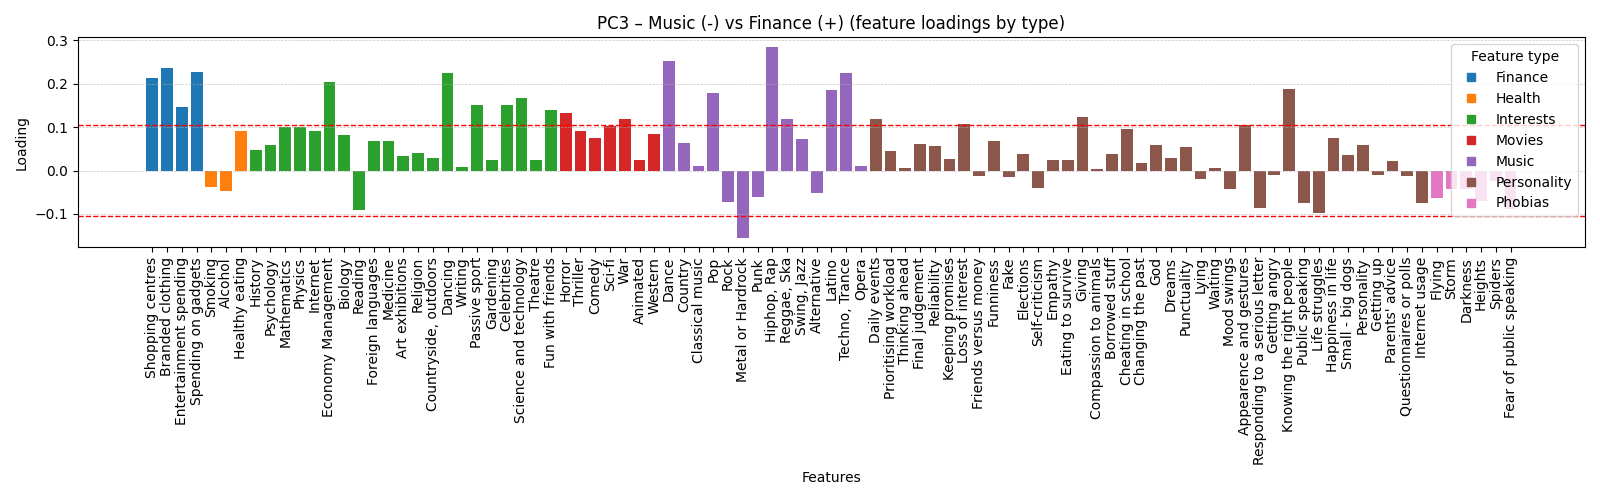


PC4 – Personality (-) vs Health (+)
  HIGH-VALUED POSITIVE COMPONENTS:
    ['Smoking', 'Alcohol', 'Mathematics', 'Physics', 'Biology', 'Medicine', 'Gardening', 'Prioritising workload', 'Thinking ahead', 'Final judgement', 'Reliability']
  HIGH-VALUED NEGATIVE COMPONENTS:
    ['Entertainment spending', 'Reading', 'Foreign languages', 'Art exhibitions', 'Theatre', 'Fun with friends', 'Horror', 'Rock', 'Punk', 'Alternative', 'Cheating in school', 'Getting up', 'Darkness', 'Spiders']


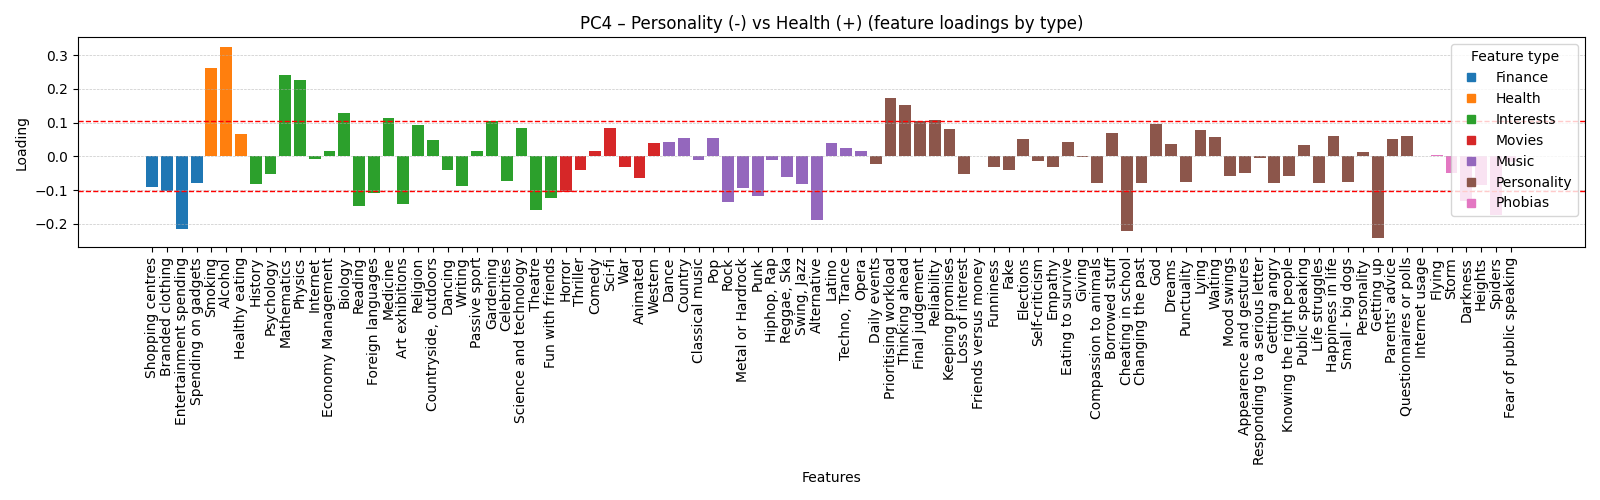


PC5 – Phobias (-) vs Personality (+)
  HIGH-VALUED POSITIVE COMPONENTS:
    ['Dancing', 'Theatre', 'Punctuality', 'Happiness in life']
  HIGH-VALUED NEGATIVE COMPONENTS:
    ['Biology', 'Science and technology', 'Thriller', 'Sci-fi', 'Animated', 'Metal or Hardrock', 'Punk', 'Techno, Trance', 'Thinking ahead', 'Final judgement', 'Fake', 'Self-criticism', 'Eating to survive', 'Changing the past', 'Mood swings', 'Getting angry', 'Public speaking', 'Spiders', 'Fear of public speaking']


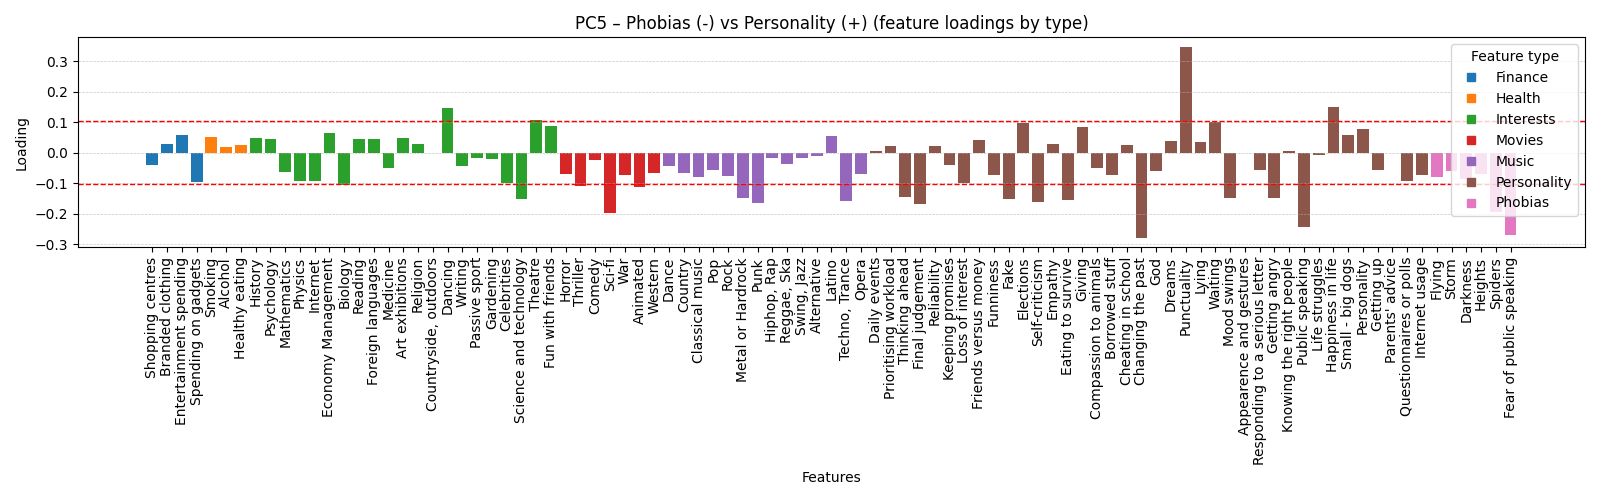

In [8]:

# 1) PCA on responses_ft_pp

pca_new = PCA()                                         # Initialize a PCA object
pca_new.fit(responses_ft_pp)                            # Fit PCA on the preprocessed data responses_ft_pp
cev_full = np.cumsum(pca_new.explained_variance_ratio_) # Compute the cumulative explained variance ratio over all PCs
m_prime = np.argmax(cev_full >= 0.33) + 1                # Find the smallest number of PCs m' such that cumulative variance ≥ 33%
m = min(m_prime, 5)                                     # m = min{m', 5}

# Print m', the chosen m, and the preserved variance 
print(f"m' (>=33% variance): {m_prime}")
print(f"Chosen m = {m}")
print(f"Preserved variance with m PCs: {cev_full[m-1]*100:.2f}%")

# 2) PCA with m components on preprocessed data
pca = PCA(n_components=m)
pca.fit(responses_ft_pp)
round_expl_var_ratio = np.round(pca.explained_variance_ratio_.sum() * 100, 2) # Total explained variance percentage by the m PCs (rounded to 2 decimals)

# 3) PLOT of explained variance of the m PCs
plt.figure(figsize=(6, 6))  
plt.bar(range(1, m + 1), pca.explained_variance_ratio_ * 100)
plt.title(f"PCs' EXPLAINED VARIANCE ({round_expl_var_ratio}% OF TOT. EXPL. VAR.)")
plt.xticks(
    ticks=np.arange(1, m + 1),
    labels=[f'PC{i}' for i in range(1, m + 1)],
    rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Percentage of explained variance')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("pca_m_explained_variance.png", dpi=300, bbox_inches='tight')
plt.show()

#  COLOURED LOADING BARPLOTS
features = responses_ft_pp.columns # feature names
n_features = pca.n_features_in_
eps = np.sqrt(1 / n_features) # threshold for "relevant" loadings

# mapping feature → type (dictionary of features by type)
features_by_type = {
    'Finance': ['Shopping centres', 'Branded clothing', 'Entertainment spending', 'Spending on gadgets'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Mathematics', 'Physics', 'Internet', 'Economy Management',
                  'Biology', 'Reading', 'Foreign languages', 'Medicine', 'Art exhibitions', 'Religion',
                  'Countryside, outdoors', 'Dancing', 'Writing', 'Passive sport', 'Gardening',
                  'Celebrities', 'Science and technology', 'Theatre', 'Fun with friends'],
    'Movies': ['Horror', 'Thriller', 'Comedy', 'Sci-fi', 'War', 'Animated', 'Western'],
    'Music': ['Dance', 'Country', 'Classical music', 'Pop', 'Rock', 'Metal or Hardrock', 'Punk',
              'Hiphop, Rap', 'Reggae, Ska', 'Swing, Jazz', 'Alternative', 'Latino',
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 'Thinking ahead', 'Final judgement',
                    'Reliability', 'Keeping promises', 'Loss of interest', 'Friends versus money',
                    'Funniness', 'Fake', 'Elections', 'Self-criticism', 'Empathy', 'Eating to survive',
                    'Giving', 'Compassion to animals', 'Borrowed stuff', 'Cheating in school',
                    'Changing the past', 'God', 'Dreams', 'Punctuality', 'Lying', 'Waiting',
                    'Mood swings', 'Appearence and gestures', 'Responding to a serious letter',
                    'Getting angry', 'Knowing the right people', 'Public speaking', 'Life struggles',
                    'Happiness in life', 'Small - big dogs', 'Personality', 'Getting up',
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Fear of public speaking']}

#assignation of the features to the type
feature_to_type = {}                        
for t, flist in features_by_type.items():   
    for f in flist:                         
        feature_to_type[f] = t              

type_colors = {
    'Finance':     '#1f77b4',
    'Health':      '#ff7f0e',
    'Interests':   '#2ca02c',
    'Movies':      '#d62728',
    'Music':       '#9467bd',
    'Personality': '#8c564b',
    'Phobias':     '#e377c2'}

# feature's colour (column order)
colors_for_features = [type_colors[feature_to_type[f]] for f in features]

# pc names until m (number of components)
pc_names = [
    'Movies (-) vs Interests (+)',
    'Phobias (-) vs Music (+)',
    'Music (-) vs Finance (+)',
    'Personality (-) vs Health (+)',
    'Phobias (-) vs Personality (+)'][:m]

# Barplots of the loadings for all m PCs, coloured by feature type 
for i in range(m):
    loadings = pca.components_[i, :]

    # indeces of below/above of features
    idx_pos = np.where(loadings >= eps)[0]
    idx_neg = np.where(loadings <= -eps)[0]

    high_pos_features = features[idx_pos].tolist()
    high_neg_features = features[idx_neg].tolist()

    print(f"\nPC{i+1} – {pc_names[i]}")
    print("  HIGH-VALUED POSITIVE COMPONENTS:")
    print("   ", high_pos_features)
    print("  HIGH-VALUED NEGATIVE COMPONENTS:")
    print("   ", high_neg_features)

    # plot 
    plt.figure(figsize=(16, 5))

    # barplot colored by type
    plt.bar(
        np.arange(n_features),
        loadings,
        color=colors_for_features)
    plt.axhline(eps,  color='red', linestyle='--', linewidth=1)
    plt.axhline(-eps, color='red', linestyle='--', linewidth=1)

    plt.xticks(
        ticks=np.arange(n_features),
        labels=features,
        rotation=90)
    plt.ylabel('Loading')
    plt.xlabel('Features')
    plt.title(f'PC{i+1} – {pc_names[i]} (feature loadings by type)')
    plt.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

    # legend
    handles = [
        plt.Line2D([], [], marker='s', linestyle='', color=col, label=t)
        for t, col in type_colors.items()]
    plt.legend(handles=handles, title='Feature type', loc='upper right')
    plt.tight_layout()
    plt.savefig(f"pc{i+1}_loadings_by_type.png", dpi=300, bbox_inches='tight')
    plt.show()



#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

PC1 – “Movies (−) vs Interests (+)”:
This principal component contrasts movie-related preferences (negative loadings) with general cultural and intellectual interests such as reading, science, medicine, and exhibitions (positive loadings). Individuals with high PC1 scores tend to show interests beyond entertainment, while low PC1 scores characterize people whose preferences are more strongly oriented toward movies. PC1 captures a first high-level distinction in lifestyle orientation.

PC2 – “Phobias (−) vs Music (+)”:
PC2 has positive loadings across many music genres, indicating general musical engagement. On the other hand, all phobias items are clearly negative, together with some anxiety-related personality traits. This means that PC2 separates people who shows more fears and emotional sensitivity from those who are more involved with music. In other words, this component describes a shift from fearful profiles to more music-oriented and emotionally expressive individuals.

PC3 – “Music (−) vs Finance (+)”:
The largest positive loadings on PC3 correspond to finance items and some health and interest variables, suggesting a consumption-oriented lifestyle. Several modern Music genres, indicating lower musical engagement, are negative. This PC therefore contrasts a materialistic orientation with a stronger focus on alternative music tastes.

PC4 – “Personality (−) vs Health (+)”:
PC4 presents variables linked to a healthy lifestyle with positive values, while smoking and alcohol have negative ones. This means that people with high PC4 scores tend to take better care of their health and avoid risky habits. On the other hand, low PC4 scores are linked to more smoking and drinking, together with less controlled or more impulsive behavior. In short, PC4 separates people with healthier daily habits from those with less healthy lifestyles.

PC5 – “Phobias (−) vs Personality (+)”:
On PC5, several Personality items such as Happiness in Life, Punctuality have high positive loadings, while many anxiety-related personality features and Phobias load strongly negatively. Interests and finance/health variables are mostly mildly positive. This axis therefore separates people with more confident, proactive personality traits from individuals characterised by stronger fears and phobic tendencies.

#### Write the code for visualizing the score graph (with PC names on the axis):

*** First rows of the m-dimensional PCA representation (responses_ft_pca) ***


,Movies (-) vs Interests (+),Phobias (-) vs Music (+),Music (-) vs Finance (+),Personality (-) vs Health (+),Phobias (-) vs Personality (+)
260,-0.984020,-0.329304,0.212690,0.440349,-0.070144
97,-0.106598,1.005863,-0.142765,0.004652,-0.244085
573,0.347365,-1.209782,0.554915,0.086146,-0.831099
649,0.919663,0.594312,-0.340795,-0.049063,-0.358534
150,0.178952,-1.150707,1.232498,-0.333176,0.246210


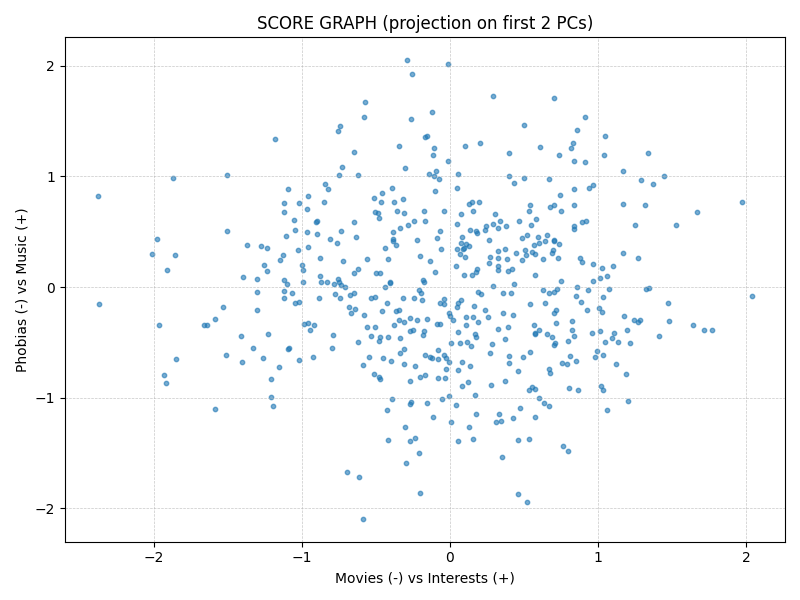

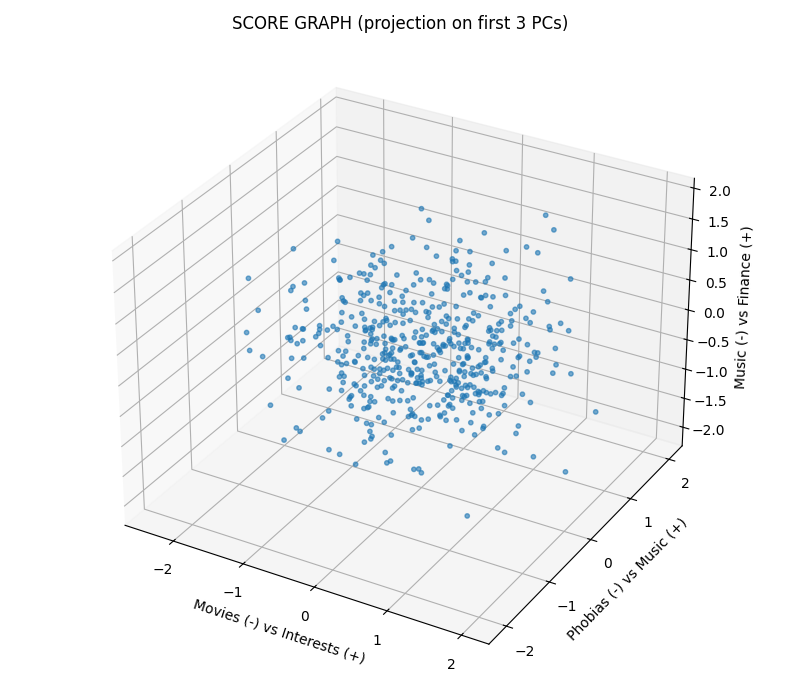

In [9]:
# 4) Transformation of the responses_ft_pp data into their m-dimensional representation via PCA

# Apply the fitted PCA (with m components) to the preprocessed data
# This projects each sample into the m-dimensional PC space
Y = pca.transform(responses_ft_pp)  

# Build a DataFrame for the PCA scores, using the same indices as the original data
# and the PC names (pc_names) as column names
responses_ft_pca = pd.DataFrame(
    Y,
    index=responses_ft_pp.index,
    columns=pc_names)
# print of the first rows 
print("*** First rows of the m-dimensional PCA representation (responses_ft_pca) ***")
display(responses_ft_pca.head())


# 5) SCORE GRAPHS

# 2D SCORE GRAPH 
if m >= 2:
    plt.figure(figsize=(8, 6))
    # Scatter plot of the scores on the first two PCs
    plt.scatter(
        responses_ft_pca[pc_names[0]],  
        responses_ft_pca[pc_names[1]],  
        s=10,                          
        alpha=0.6)
    
    plt.title("SCORE GRAPH (projection on first 2 PCs)")
    plt.xlabel(pc_names[0])
    plt.ylabel(pc_names[1])    
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)    
    plt.tight_layout()   
    plt.savefig("scoregraph_2D.png", dpi=300, bbox_inches='tight')
    plt.show()

# 3D SCORE GRAPH 
if m > 3:
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection='3d')
    # Scatter plot of the scores on the first three PCs
    ax.scatter(
        responses_ft_pca[pc_names[0]],  
        responses_ft_pca[pc_names[1]],  
        responses_ft_pca[pc_names[2]],  
        s=10,                           
        alpha=0.6)

    ax.set_title("SCORE GRAPH (projection on first 3 PCs)")
    ax.set_xlabel(pc_names[0])
    ax.set_ylabel(pc_names[1])
    ax.set_zlabel(pc_names[2])
    plt.tight_layout()
    plt.savefig("scoregraph_3D.png", dpi=300, bbox_inches='tight')
    plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

k =  3  -> silhouette score = 0.1771
k =  4  -> silhouette score = 0.1793
k =  5  -> silhouette score = 0.1576
k =  6  -> silhouette score = 0.1556
k =  7  -> silhouette score = 0.1550
k =  8  -> silhouette score = 0.1588
k =  9  -> silhouette score = 0.1575
k = 10  -> silhouette score = 0.1462


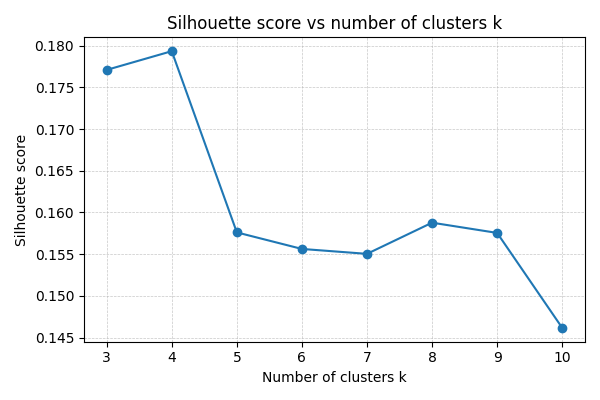


****************** AVG SILHOUETTE SCORE ******************
Best k = 4
**********************************************************


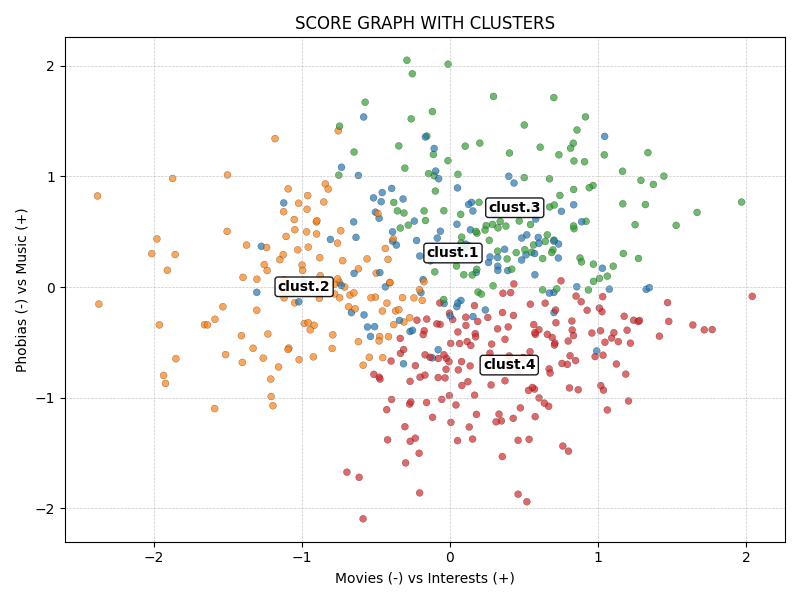

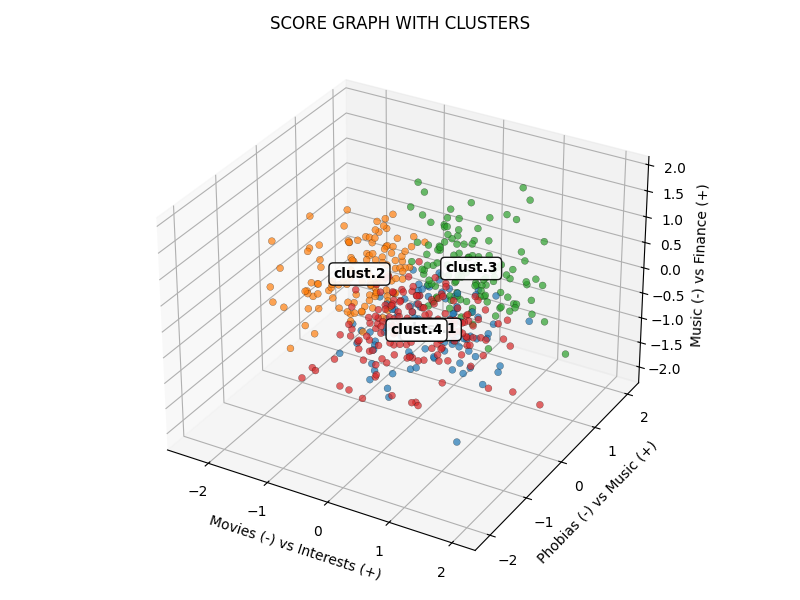

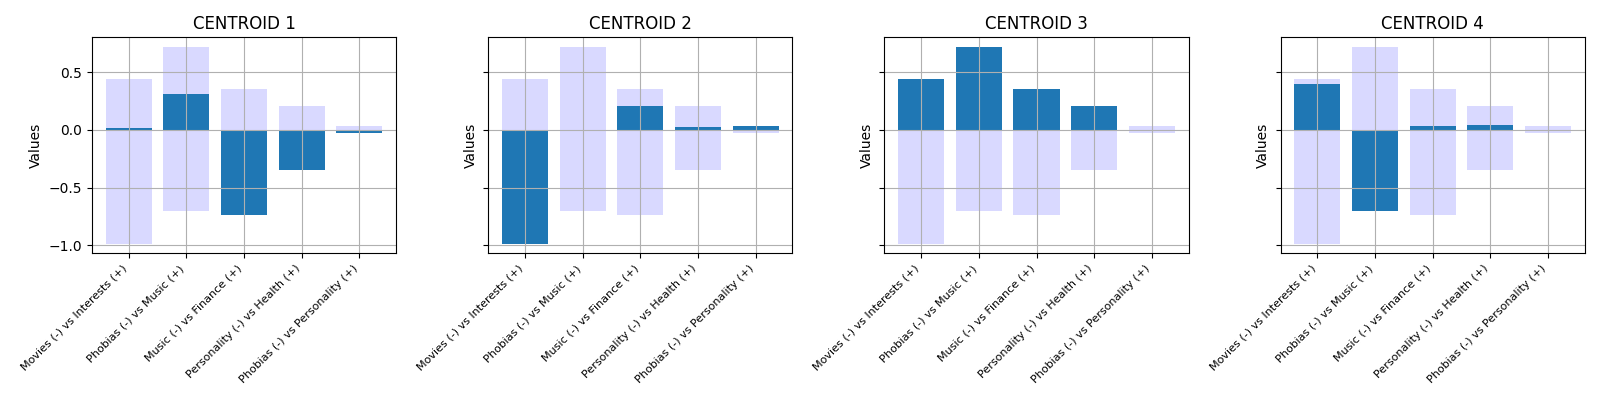

In [10]:
# 1) K-means for clustering responses_ft_pca
X_pca = responses_ft_pca[pc_names].values  # build the PCA data matrix 
k_values   = range(3, 11)                  # candidate numbers of clusters
sil_scores = []                            # initialize list that will store one silhouette score for each k

for k in k_values:                                              
    kmeans   = KMeans(n_clusters=k,                             # create a KMeans object with k clusters
                      random_state=random_seed,                 # fix random seed for reproducibility
                      n_init=10)                                # fix number of initializations
    labels_k = kmeans.fit_predict(X_pca)                        # fit KMeans on X_pca and get the cluster labels for each sample
    sil      = silhouette_score(X_pca, labels_k)                # compute the average silhouette score for this clustering
    sil_scores.append(sil)                                      # store the silhouette score corresponding to this k
    print(f"k = {k:2d}  -> silhouette score = {sil:.4f}")       # print k and its silhouette score

# PLOT
# plot how the score changes w.r.t. k
plt.figure(figsize=(6, 4))
plt.plot(list(k_values), sil_scores, marker='o')
plt.title('Silhouette score vs number of clusters k')
plt.xlabel('Number of clusters k')
plt.ylabel('Silhouette score')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("kmeans_silhouette_scores.png", dpi=300, bbox_inches='tight')
plt.show()

best_k = k_values[int(np.argmax(sil_scores))]
print(f"\n****************** AVG SILHOUETTE SCORE ******************")
print(f"Best k = {best_k}")
print("**********************************************************")

# 2) Fit k-Means with best_k and plot score graphs
kmeans_best = KMeans(n_clusters=best_k, random_state=random_seed, n_init=10) # create final KMeans model with the best number of clusters (best_k),
cluster_0base = kmeans_best.fit_predict(X_pca) # fit KMeans on the PCA data X_pca and get cluster labels for each sample
centroids = kmeans_best.cluster_centers_       # store the coordinates of the cluster centroids in PCA space
cluster_ids = cluster_0base + 1                # convert 0-based cluster labels to 1-based 
responses_ft_pca['cluster'] = cluster_ids      # add the 1-based cluster labels as a new column 'cluster' in the PCA scores DataFrame

# define a color palette with clearly distinct colors
cluster_palette = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
colors_points = [cluster_palette[c] for c in cluster_0base]

# SCORE GRAPH 2D
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=colors_points,
    s=25, alpha=0.7,
    edgecolors='k', linewidths=0.2)

for c in range(best_k):
    plt.text(
        centroids[c, 0], centroids[c, 1],
        f'clust.{c+1}',
        ha='center', va='center',
        fontsize=10, fontweight='bold',
        color='black',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='black', alpha=0.9))

plt.title('SCORE GRAPH WITH CLUSTERS')
plt.xlabel(pc_names[0])
plt.ylabel(pc_names[1])
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("kmeans_scoregraph_2D.png", dpi=300, bbox_inches='tight')
plt.show()

# SCORE GRAPH 3D
if m >= 3:
    fig_k3d = plt.figure(figsize=(8, 6))
    ax = fig_k3d.add_subplot(111, projection='3d')

    ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=colors_points,
        s=25, alpha=0.7,
        edgecolors='k', linewidths=0.2)

    for c in range(best_k):
        ax.text(
            centroids[c, 0], centroids[c, 1], centroids[c, 2],
            f'clust.{c+1}',
            ha='center', va='center',
            fontsize=10, fontweight='bold',
            color='black',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='black', alpha=0.9))

    ax.set_title('SCORE GRAPH WITH CLUSTERS')
    ax.set_xlabel(pc_names[0])
    ax.set_ylabel(pc_names[1])
    ax.set_zlabel(pc_names[2])
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.tight_layout()
    plt.savefig("kmeans_scoregraph_3D.png", dpi=300, bbox_inches='tight')
    plt.show()

# 3) Centroids as barplots 
mins_pcs = centroids.min(axis=0)
maxs_pcs = centroids.max(axis=0)

fig, axes = plt.subplots(
    1, best_k, figsize=(4 * best_k, 4), sharey=True
)
if best_k == 1:
    axes = [axes]  

for c in range(best_k):
    ax = axes[c]
    ax.bar(np.arange(m), maxs_pcs, color='blue', alpha=0.15)
    ax.bar(np.arange(m), mins_pcs, color='blue', alpha=0.15)
    ax.bar(np.arange(m), centroids[c, :])
    ax.set_xticks(np.arange(m))
    ax.set_xticklabels(pc_names, rotation=45, ha='right', fontsize=8)
    ax.grid(visible=True, which='both')
    ax.set_title(f'CENTROID {c+1}')
    ax.set_ylabel('Values')


fig.tight_layout()
fig.savefig("kmeans_centroids_barplots.png", dpi=300, bbox_inches='tight')
plt.show()

#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):

Centroid 1 – Music-oriented person:
This profile is almost neutral on the first and the last pcs , so there is no clear preference between movies and general interests and, phobias and personality. It shows positive values on the second pc, indicating some engagement with music. The centroid is clearly negative on the pc3, meaning it is closer to the music side than to the finance side. It is also negative on pc4, suggesting a lower focus on healthy habits.

Centroid 2 – Movie passionate person:
This profile is strongly negative on pc1, clearly pointing to a preference for movies over interests. Most other components are close to zero, except for a slightly positive value on pc3, which suggests some attention to practical or financial aspects. There is no clear orientation toward music, phobias, health, or personality traits in this group.

Centroid 3 – Active and engaged person:
This profile is positive on  all the first four principal components, in order pc2, pc1, pc3, pc4.This indicates a strong interest in general activities beyond movies, high musical engagement and low fear-related tendencies. In addition, we also have a mix of practical orientation and healthier habits. Overall, this is the most active and involved profile.


Centroid 4 – Interested and fearful person:
This profile is positive on pc1, so it is oriented toward general interests rather than movies. At the same time, it is strongly negative on pc2, indicating higher levels of fears and lower engagement with music. The remaining components are close to zero and do not strongly characterize this group. The main distinction of this profile lies in the combination of high interests and higher phobias.



## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

Age is an important label because people’s interests, health habits, and fears often change as they get older. The use of this label helps us to verify whether the clusters corresponds to different life stages and preference patterns.

Gender can influence music tastes, fears, and health-related behaviours. Looking at gender helps to check whether the clusters reflect common or different behaviours based on gender.

Education level is often related to cultural interests, lifestyle, some personality traits and attention to health. Using it as a label helps to check whether clusters separate people with different school/university backgrounds and education levels.

#### Write the code for the visualizations cited in item 2 above:

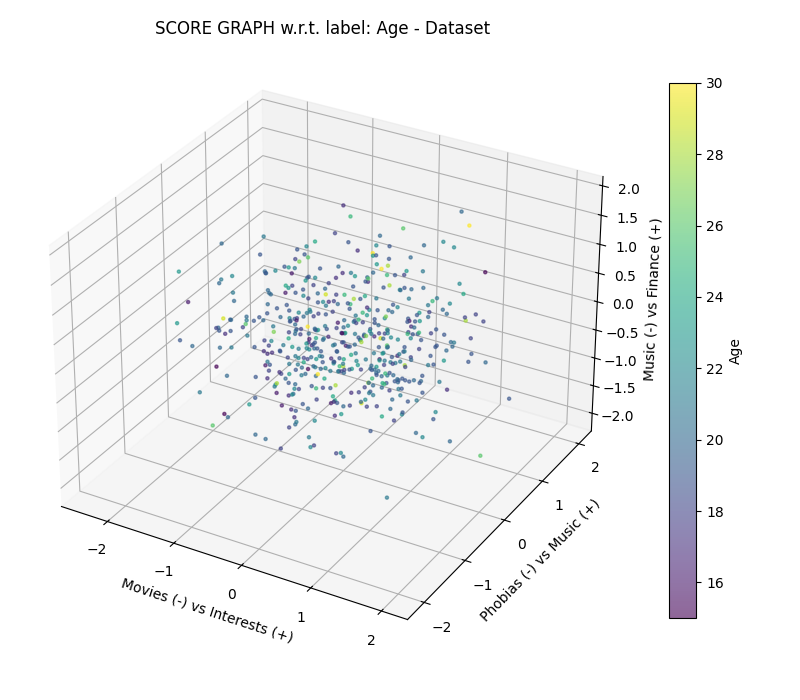

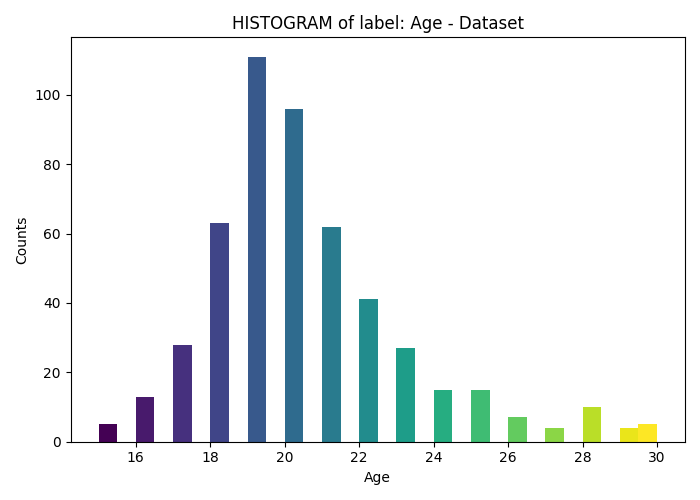

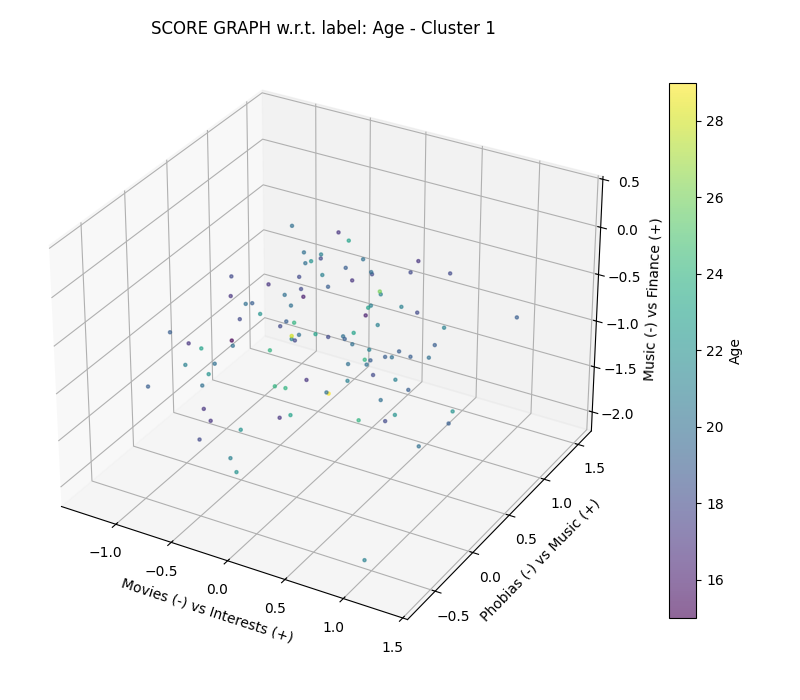

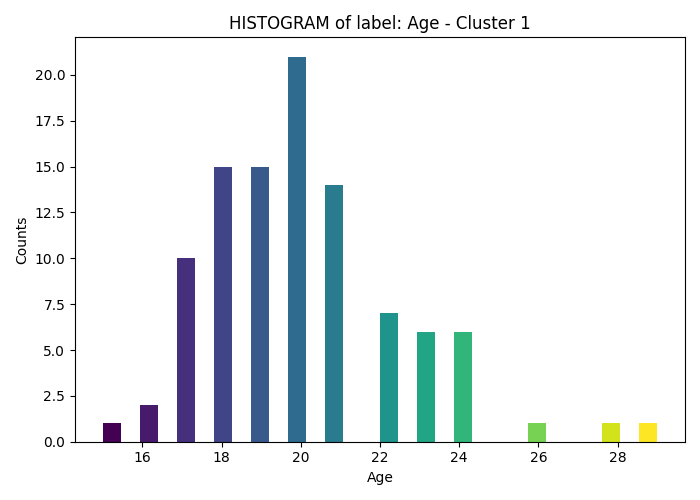

C:\Users\Administrator\AppData\Local\Temp\ipykernel_20660\1832888268.py:115: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(8, 7))


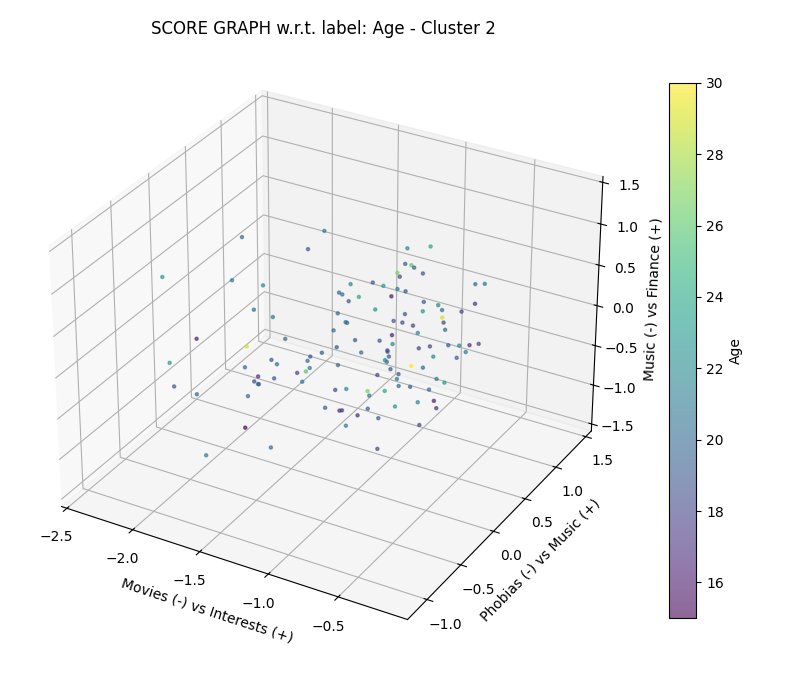

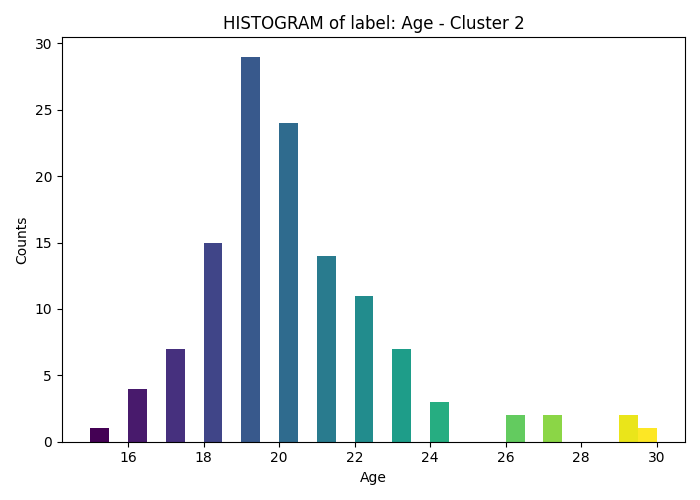

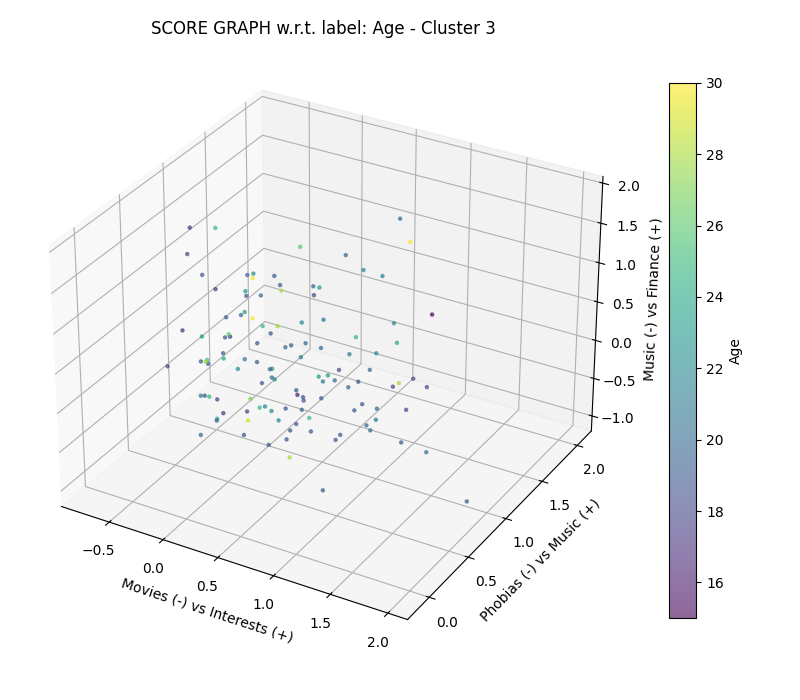

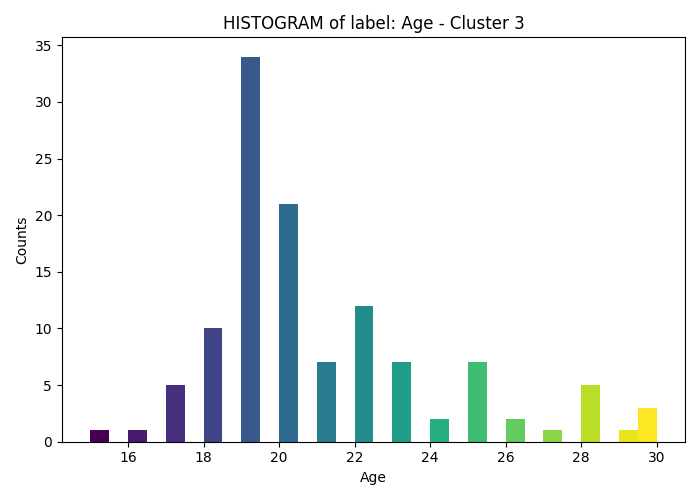

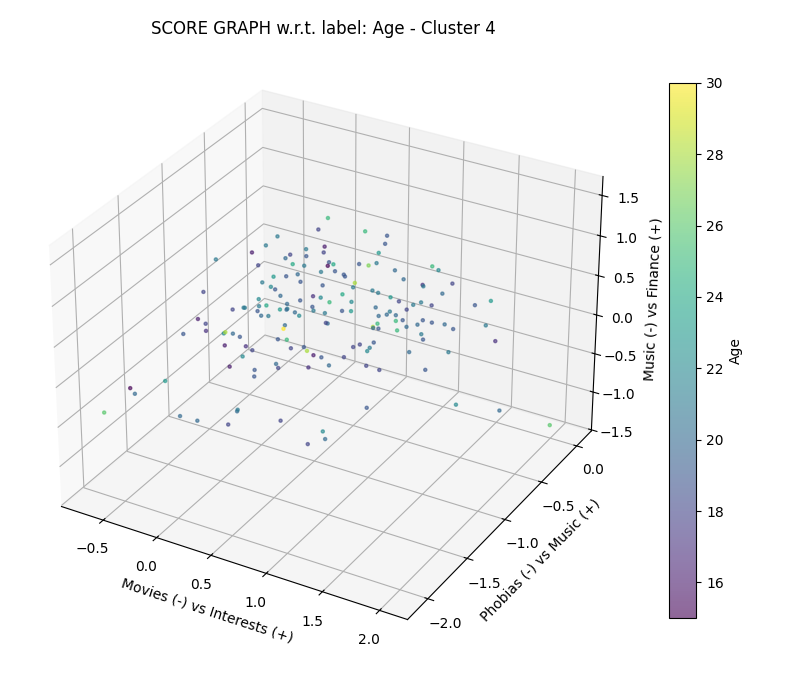

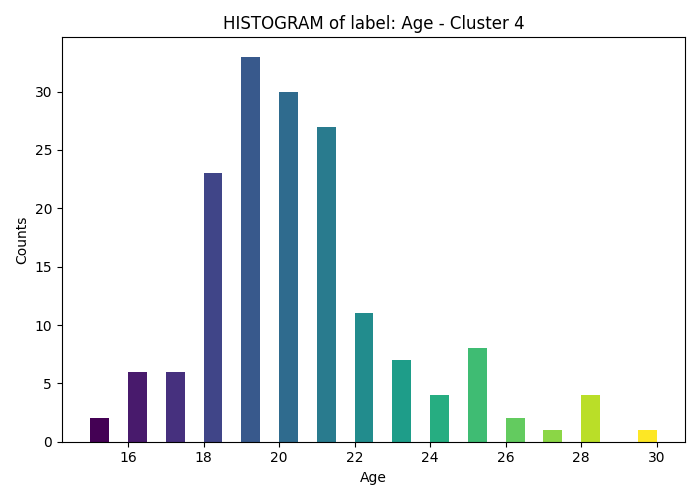

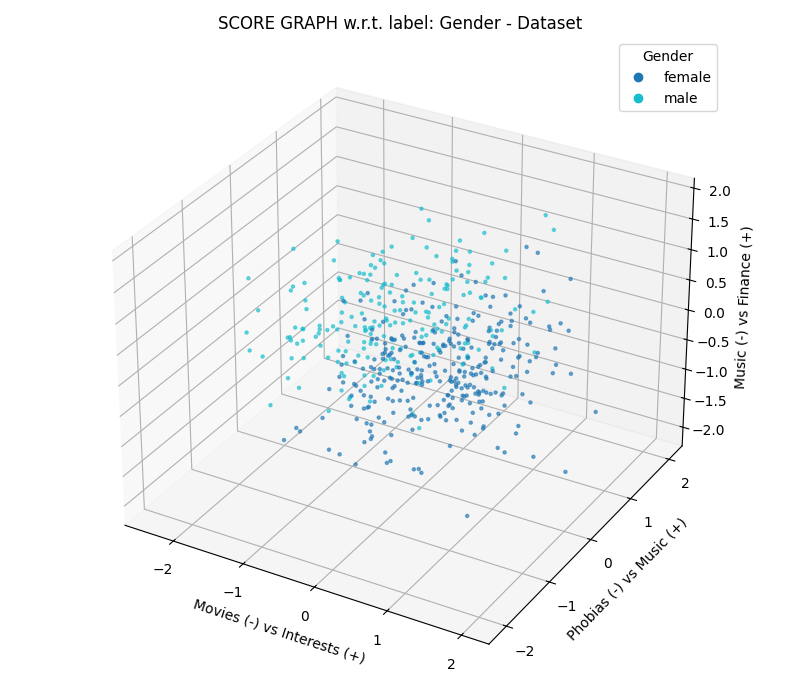

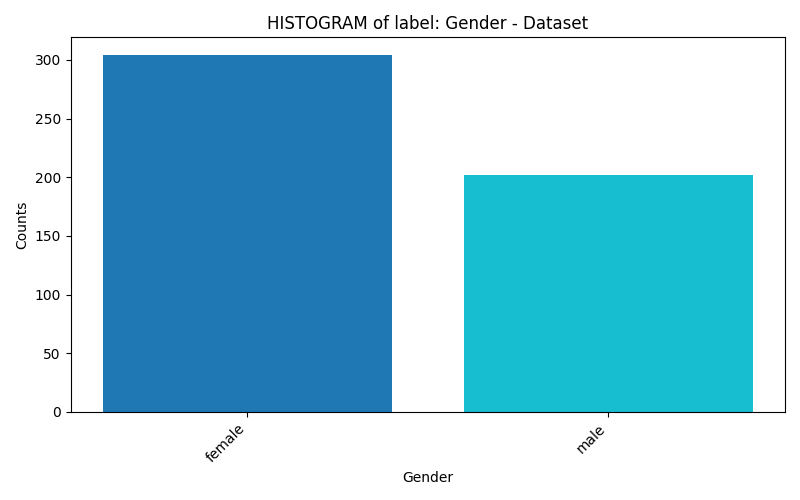

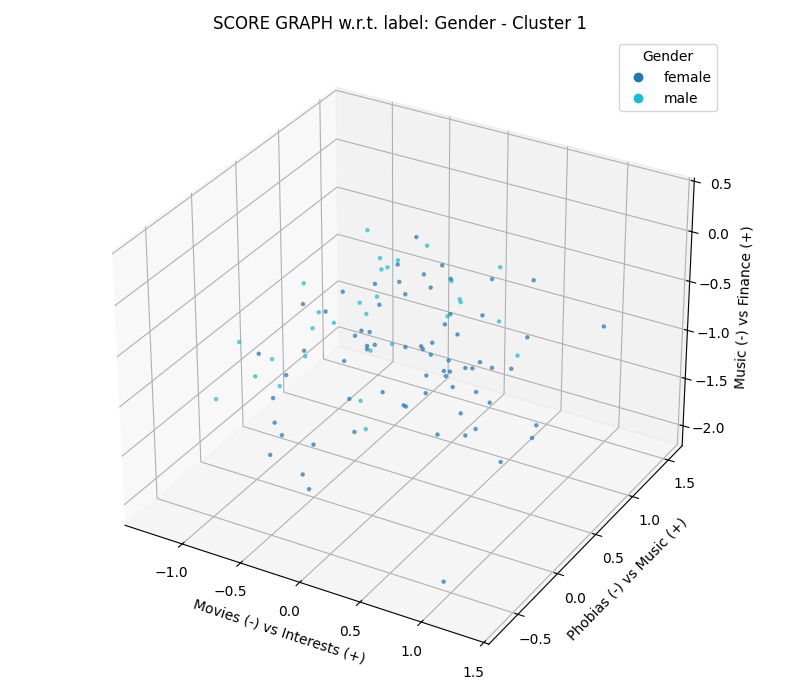

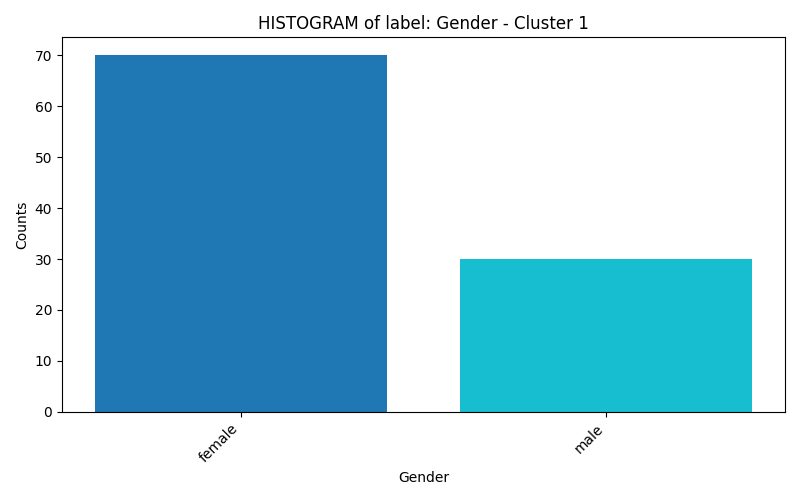

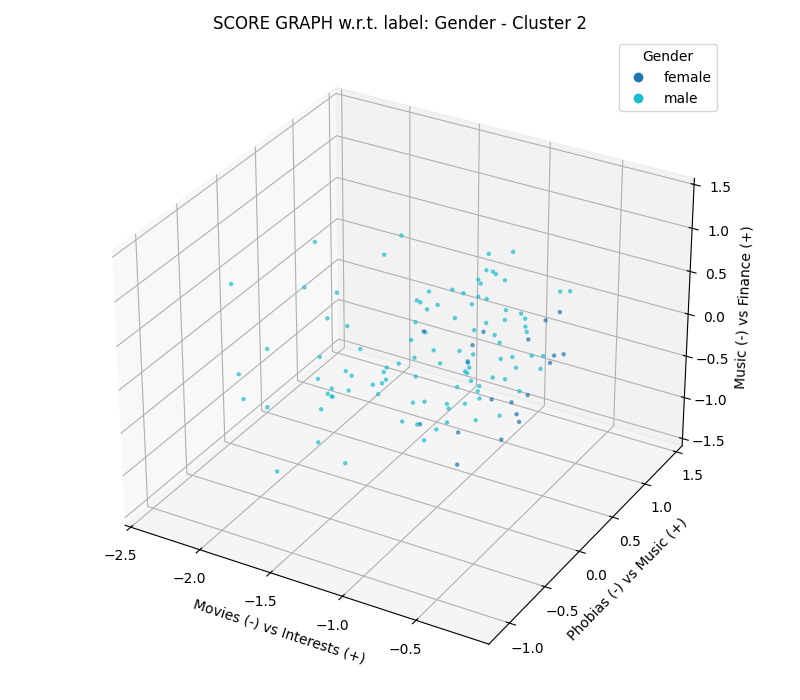

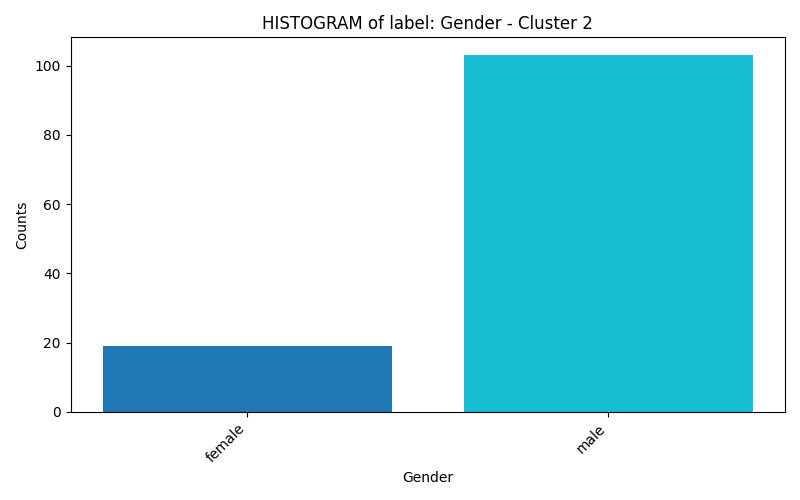

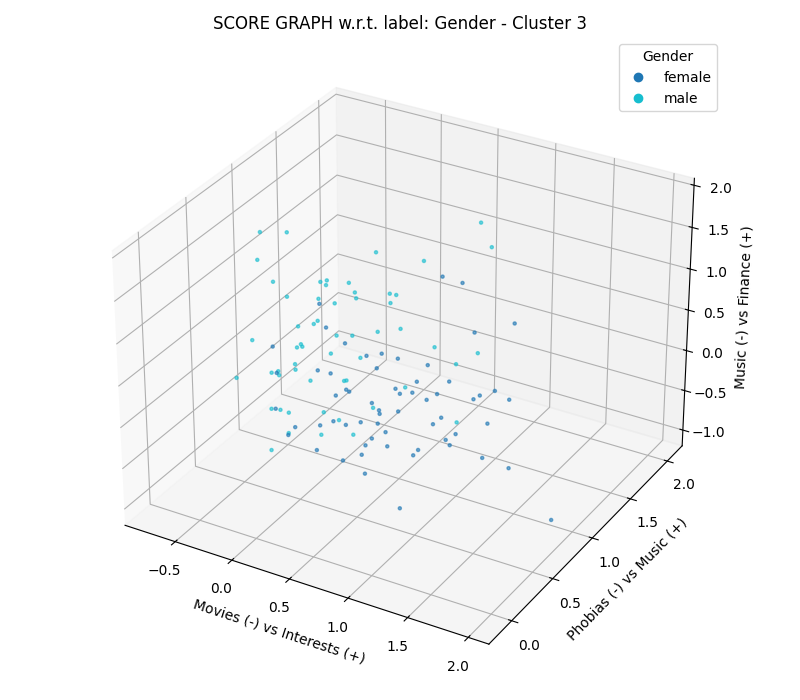

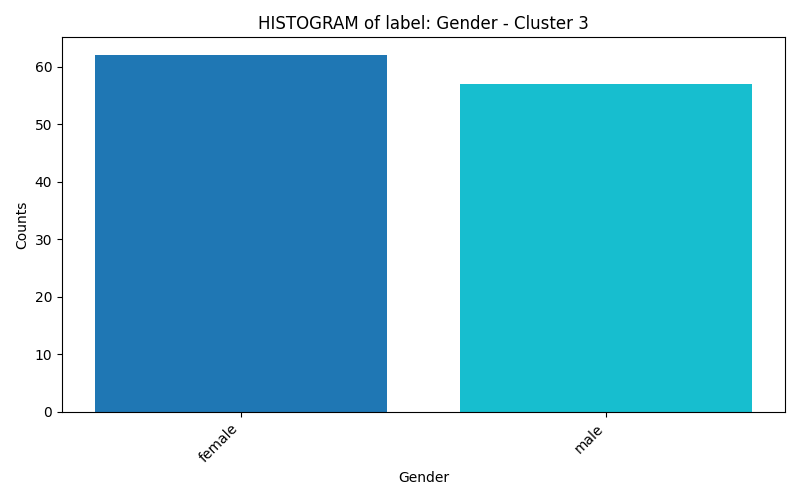

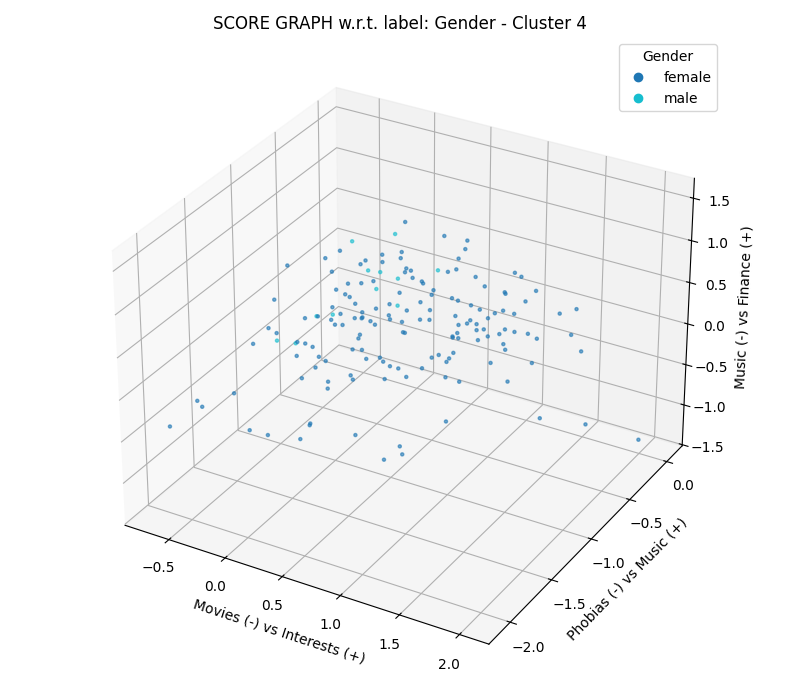

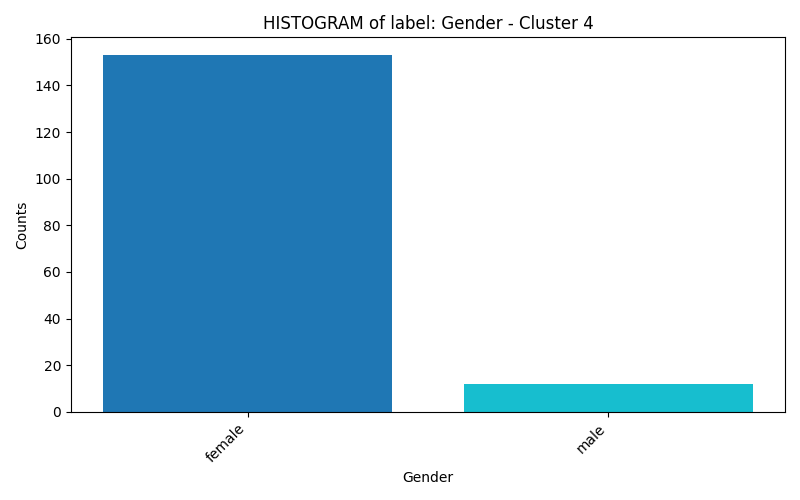

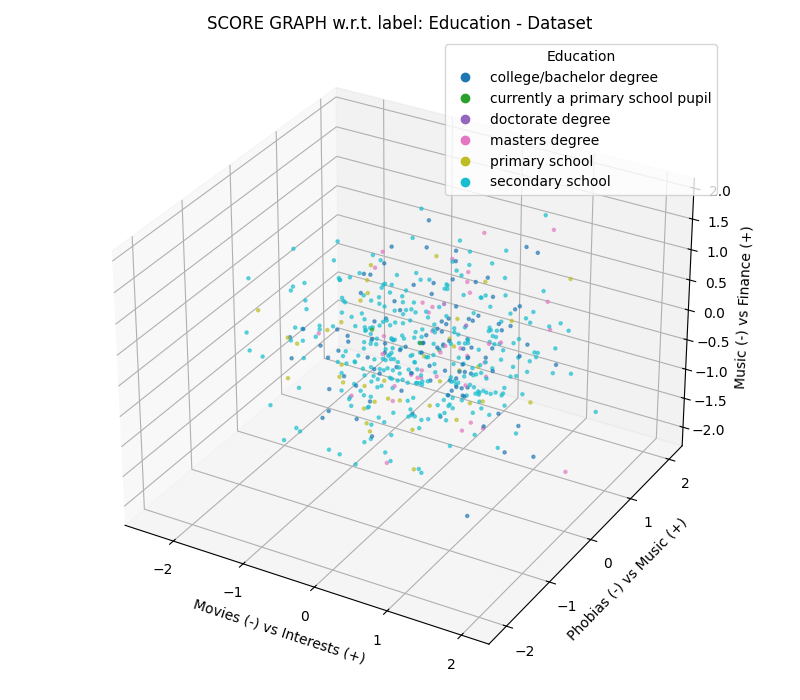

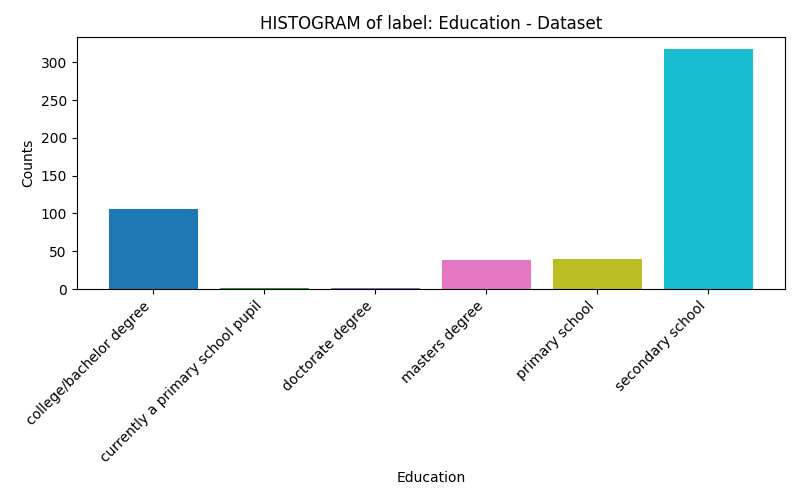

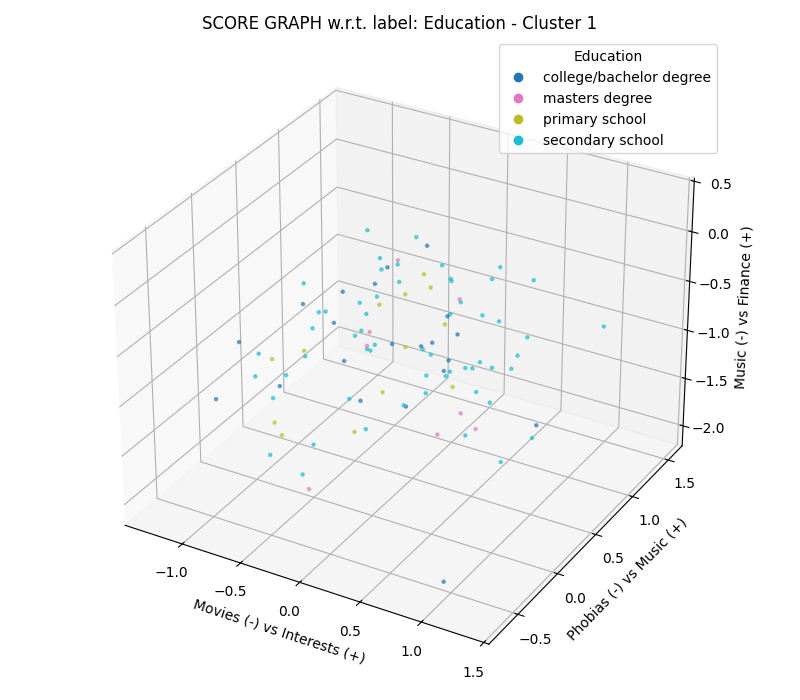

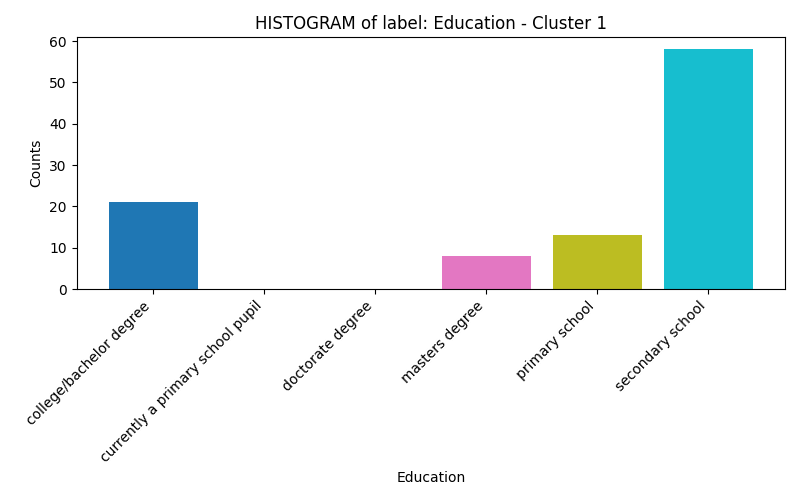

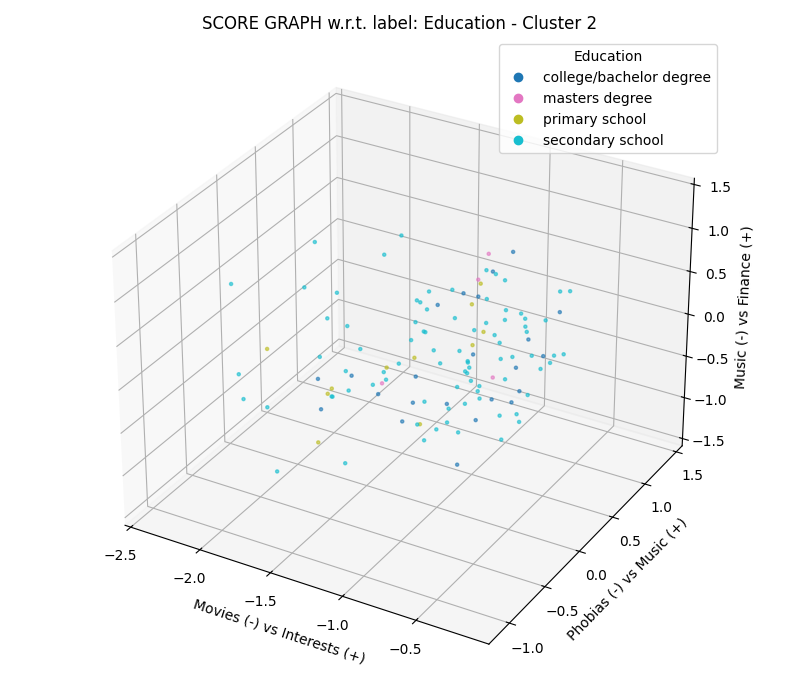

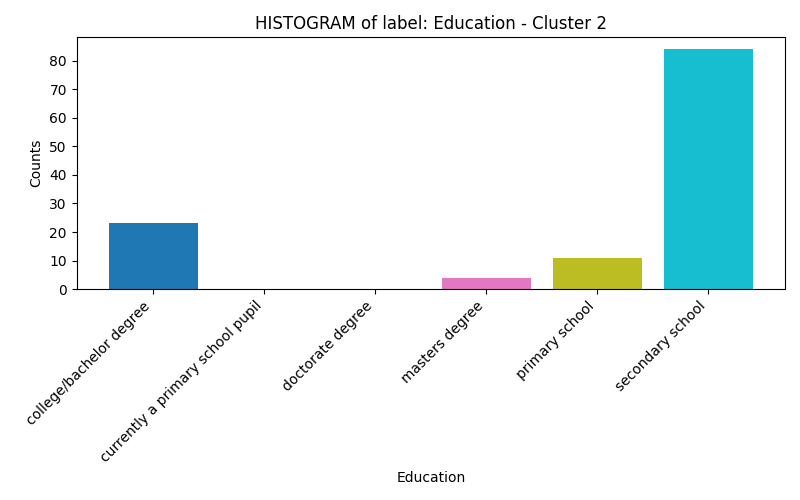

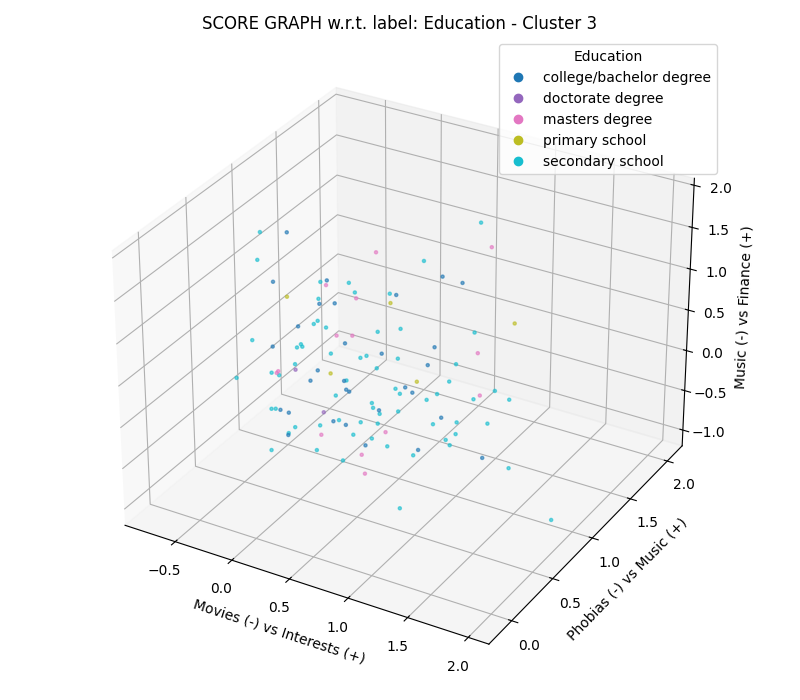

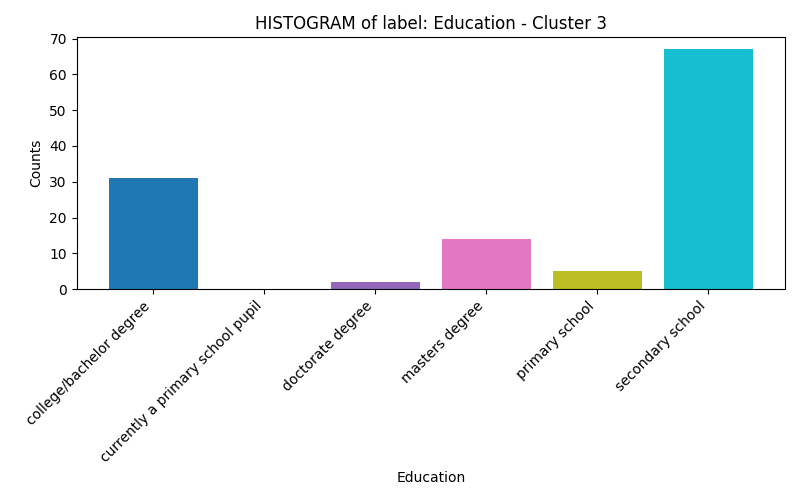

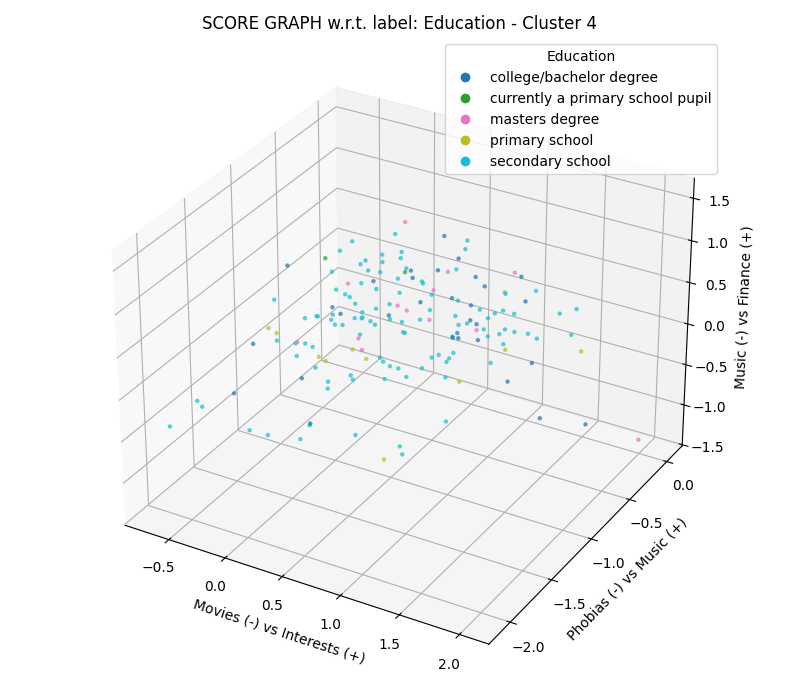

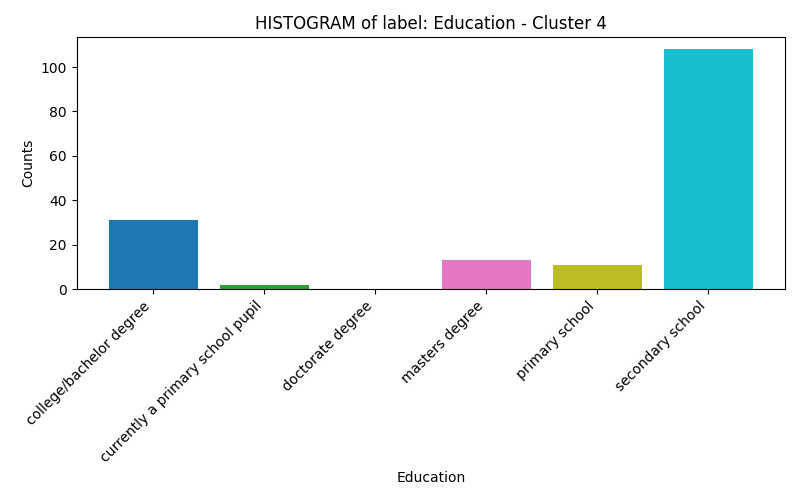

In [11]:
# External cluster evaluation plots
selected_labels = ['Age', 'Gender', 'Education'] # List of chosen labels

# Intersection between indices of PCA+cluster dataframe and original labels dataframe
common_idx = responses_ft_pca.index.intersection(responses_lb.index)

# Create a DataFrame that contains only those common rows, it includes the PCs and the 'cluster' column
scores = responses_ft_pca.loc[common_idx].copy()
# Create a smaller labels DataFrame with only the selected labels and only for the common indices
labels_subset = responses_lb.loc[common_idx, selected_labels].copy() 
clusters = scores['cluster'].to_numpy()  # Extract the cluster assignments
scores_pc = scores[pc_names].to_numpy()  # Extract the PCA scores (coordinates in PC space) using the columns listed in pc_names
n_clusters = int(clusters.max())         # Compute the number of clusters as the maximum cluster index


# PLOT
for label_name in selected_labels:
    label_vals = labels_subset[label_name]                  # Extract the values of the current label for all samples
    is_numeric = np.issubdtype(label_vals.dtype, np.number) # Check if the label is numeric or categorical

 
    # FIXED COLOR MAP (categorical)

    # Build a dataset-wide mapping category -> color 
    if not is_numeric:
        categories_all = np.unique(label_vals)              
        cmap_cat = plt.colormaps['tab10']                   
        cat_to_color = {                                    
            cat: cmap_cat(i / max(len(categories_all) - 1, 1))
            for i, cat in enumerate(categories_all)}

# DATASET
    if is_numeric:
        # 3D score graph
        fig = plt.figure(figsize=(8, 7))
        ax = fig.add_subplot(111, projection='3d')
        cmap = plt.colormaps['viridis']
        sc = ax.scatter(scores_pc[:, 0], scores_pc[:, 1], scores_pc[:, 2],
                        c=label_vals, cmap=cmap, s=5, alpha=0.6)
        ax.set_xlabel(pc_names[0])
        ax.set_ylabel(pc_names[1])
        ax.set_zlabel(pc_names[2])
        ax.set_title(f'SCORE GRAPH w.r.t. label: {label_name} - Dataset')
        fig.colorbar(sc, ax=ax, shrink=0.8, label=label_name)
        plt.tight_layout()
        plt.savefig(f"score3D_{label_name}_dataset.png",
                    dpi=300, bbox_inches='tight')
        plt.show()

        # Histogram
        fig, ax = plt.subplots(figsize=(7, 5))
        n_bins = 30
        counts, bins, patches = ax.hist(label_vals, bins=n_bins)
        cmap_hist = plt.colormaps['viridis']
        for c, p in zip(np.linspace(0, 1, len(patches)), patches):
            p.set_facecolor(cmap_hist(c))
        ax.set_xlabel(label_name)
        ax.set_ylabel('Counts')
        ax.set_title(f'HISTOGRAM of label: {label_name} - Dataset')
        plt.tight_layout()
        plt.savefig(f"hist_{label_name}_dataset.png",
                    dpi=300, bbox_inches='tight')
        plt.show()

    else:
        # 3D score graph
        fig = plt.figure(figsize=(8, 7))
        ax = fig.add_subplot(111, projection='3d')
        colors = [cat_to_color[v] for v in label_vals]
        ax.scatter(scores_pc[:, 0], scores_pc[:, 1], scores_pc[:, 2],
                   c=colors, s=5, alpha=0.6)
        handles = [
            plt.Line2D([], [], marker='o', linestyle='',
                       color=cat_to_color[cat],
                       label=str(cat))
            for cat in categories_all
        ]
        ax.legend(handles=handles, title=label_name, loc='upper right')

        ax.set_xlabel(pc_names[0])
        ax.set_ylabel(pc_names[1])
        ax.set_zlabel(pc_names[2])
        ax.set_title(f'SCORE GRAPH w.r.t. label: {label_name} - Dataset')
        plt.tight_layout()
        plt.savefig(f"score3D_{label_name}_dataset.png",
                    dpi=300, bbox_inches='tight')
        plt.show()

        # Barplot
        fig, ax = plt.subplots(figsize=(8, 5))
        categories, counts = np.unique(label_vals, return_counts=True)
        counts_dict = dict(zip(categories, counts))
        counts_all = [counts_dict.get(cat, 0) for cat in categories_all]
        colors_all = [cat_to_color[cat] for cat in categories_all]

        ax.bar(categories_all, counts_all, color=colors_all)
        ax.set_xlabel(label_name)
        ax.set_ylabel('Counts')
        ax.set_title(f'HISTOGRAM of label: {label_name} - Dataset')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
        plt.tight_layout()
        plt.savefig(f"bar_{label_name}_dataset.png",
                    dpi=300, bbox_inches='tight')
        plt.show()

# PLOT FOR EACH CLUSTER
    for k in range(1, n_clusters + 1):
        mask = clusters == k
        label_vals_k = label_vals[mask]
        scores_pc_k = scores_pc[mask, :]
        suffix = f'Cluster {k}'

        if is_numeric:
            # 3D score graph cluster k
            fig = plt.figure(figsize=(8, 7))
            ax = fig.add_subplot(111, projection='3d')
            cmap = plt.colormaps['viridis']
            sc = ax.scatter(scores_pc_k[:, 0], scores_pc_k[:, 1], scores_pc_k[:, 2],
                            c=label_vals_k, cmap=cmap, s=5, alpha=0.6)
            ax.set_xlabel(pc_names[0])
            ax.set_ylabel(pc_names[1])
            ax.set_zlabel(pc_names[2])
            ax.set_title(f'SCORE GRAPH w.r.t. label: {label_name} - {suffix}')
            fig.colorbar(sc, ax=ax, shrink=0.8, label=label_name)
            plt.tight_layout()
            plt.savefig(f"score3D_{label_name}_cluster{k}.png",
                        dpi=300, bbox_inches='tight')
            plt.show()

            # Histogram cluster k
            fig, ax = plt.subplots(figsize=(7, 5))
            counts_k, bins_k, patches_k = ax.hist(label_vals_k, bins=n_bins)
            cmap_hist = plt.colormaps['viridis']
            for c, p in zip(np.linspace(0, 1, len(patches_k)), patches_k):
                p.set_facecolor(cmap_hist(c))
            ax.set_xlabel(label_name)
            ax.set_ylabel('Counts')
            ax.set_title(f'HISTOGRAM of label: {label_name} - {suffix}')
            plt.tight_layout()
            plt.savefig(f"hist_{label_name}_cluster{k}.png",
                        dpi=300, bbox_inches='tight')
            plt.show()

        else:
            # 3D score graph cluster k
            fig = plt.figure(figsize=(8, 7))
            ax = fig.add_subplot(111, projection='3d')
            colors_k = [cat_to_color[v] for v in label_vals_k]
            ax.scatter(scores_pc_k[:, 0], scores_pc_k[:, 1], scores_pc_k[:, 2],
                       c=colors_k, s=5, alpha=0.6)
            categories_k = np.unique(label_vals_k)
            handles = [
                plt.Line2D([], [], marker='o', linestyle='',
                           color=cat_to_color[cat],
                           label=str(cat))
                for cat in categories_k
            ]
            ax.legend(handles=handles, title=label_name, loc='upper right')

            ax.set_xlabel(pc_names[0])
            ax.set_ylabel(pc_names[1])
            ax.set_zlabel(pc_names[2])
            ax.set_title(f'SCORE GRAPH w.r.t. label: {label_name} - {suffix}')
            plt.tight_layout()
            plt.savefig(f"score3D_{label_name}_cluster{k}.png",
                        dpi=300, bbox_inches='tight')
            plt.show()

            # Barplot cluster k
            fig, ax = plt.subplots(figsize=(8, 5))
            categories_k, counts_k = np.unique(label_vals_k, return_counts=True)
            counts_dict_k = dict(zip(categories_k, counts_k))
            counts_all_k = [counts_dict_k.get(cat, 0) for cat in categories_all]
            colors_all_k = [cat_to_color[cat] for cat in categories_all]

            ax.bar(categories_all, counts_all_k, color=colors_all_k)
            ax.set_xlabel(label_name)
            ax.set_ylabel('Counts')
            ax.set_title(f'HISTOGRAM of label: {label_name} - {suffix}')
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
            plt.tight_layout()
            plt.savefig(f"bar_{label_name}_cluster{k}.png",
                        dpi=300, bbox_inches='tight')
            plt.show()


#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

Concerning the label age, all clusters are mainly composed of young individuals, with most ages concentrated between 18 and 22 years. However, there are small visible differences between clusters: clusters 3 and 4 show a wider age spread and include more observations above 23–24 years, reaching up to 29–30, while Clusters 1 and 2 are more concentrated around 18–21 with fewer older individuals.
The 3D score plots confirm that age values are mixed within each cluster, but the presence of slightly older subjects in clusters 3 and 4 suggests a modest age shift rather than a sharp separation.

First of all, concerning the label gender the dataset histogram shows more females than males overall. Looking at clusters, Cluster 1 and Cluster 4 are clearly female-dominated, while Cluster 2 is strongly male-dominated. Cluster 3 appears more balanced between genders. These differences are clearly visible in the barplots and consistent in the 3D score graphs. Thus gender meaningfully differentiates clusters, especially separating Cluster 2 from Clusters 1 and 4.

About the label education, from the dataset histogram, we can clearly see that secondary school is the most frequent education level, followed by college/bachelor degree, while master, primary school, doctorate and current pupil appear much less frequently.
Looking at the cluster histograms, all clusters are still dominated by secondary school, but the proportions change: clusters 3 and 4 also include master degree and rare categories such as doctorate or current pupil, which are absent or almost absent in Clusters 1 and 2.
Even if in the 3D plots, individuals with different education levels are mixed together, the histograms show that some education levels are more common in certain clusters than in others.

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

Sil. Score


,Sil. Score
Music-oriented person,0.132111
Movie passionate person,0.194438
Active and engaged person,0.163667
Interested and fearful person,0.208106
Global average,0.179341


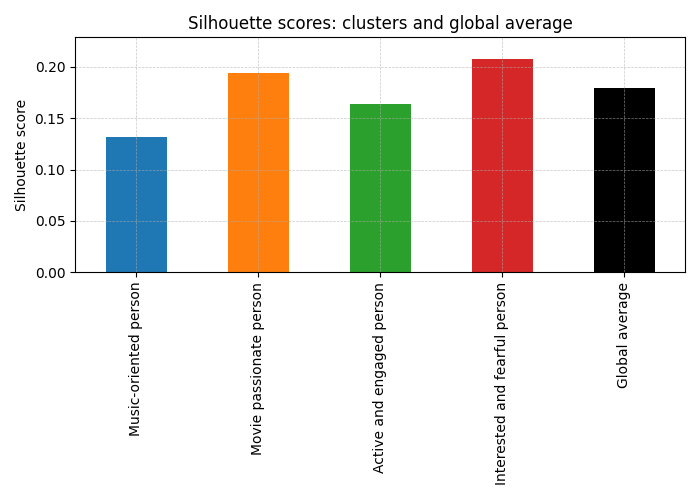

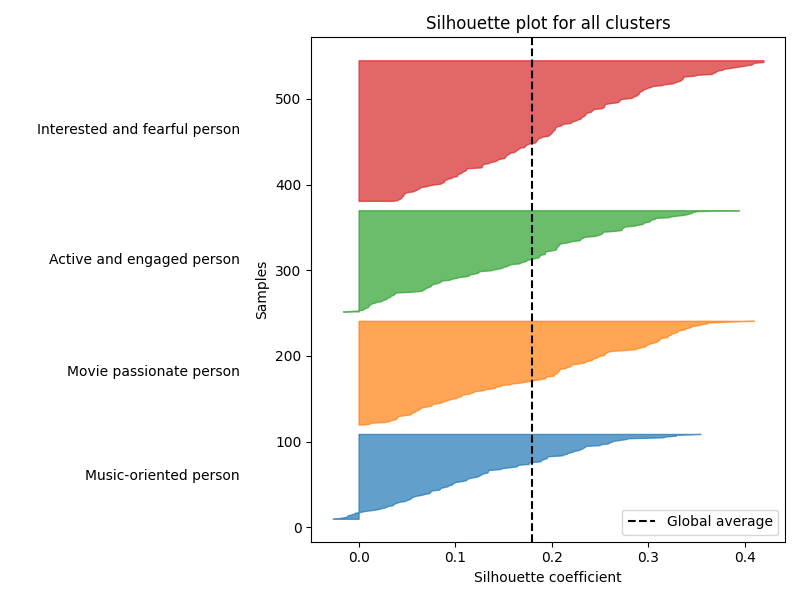

In [12]:
# Cluster names (1–based)
cluster_names = {
    1: "Music-oriented person",
    2: "Movie passionate person",
    3: "Active and engaged person",
    4: "Interested and fearful person"
}

# Colors associated to each cluster
cluster_colors = {
    1: "tab:blue",
    2: "tab:orange",
    3: "tab:green",
    4: "tab:red"
}

sil_global = silhouette_score(scores_pc, clusters)    # Compute the global silhouette score (single value for the whole clustering)
sil_samples = silhouette_samples(scores_pc, clusters) # Compute the silhouette score for each individual sample 
cluster_sil = {}                                     


# Loop over cluster IDs from 1 to n_clusters (because clusters are 1–based)
for c in range(1, n_clusters + 1):
    mask = (clusters == c)                           # Create a boolean mask selecting the points belonging to cluster c
    cluster_sil[c] = sil_samples[mask].mean()        # Compute the mean silhouette score of the points in cluster c

sil_series = pd.Series(cluster_sil)

# Replace the numeric index with cluster names
sil_series.index = [cluster_names[c] for c in range(1, n_clusters + 1)]

# Convert the Series into a DataFrame with a single column named "Sil. Score"
sil_df = sil_series.to_frame(name='Sil. Score')
sil_df.loc['Global average'] = sil_global   # Add an extra row with the global silhouette score
print('Sil. Score')                         # Print a header
display(sil_df)

plt.figure(figsize=(7, 5))
all_scores = sil_series.copy()                      # Make a copy of the per-cluster Series to add the global value
all_scores.loc['Global average'] = sil_global       # Add the global silhouette score as an additional entry

# Colors for barplot (clusters + global)
bar_colors = [cluster_colors[c] for c in range(1, n_clusters + 1)] + ["black"]

all_scores.plot(kind='bar', color=bar_colors)
plt.ylabel('Silhouette score')
plt.title('Silhouette scores: clusters and global average')
plt.ylim(min(0, all_scores.min() * 1.1), all_scores.max() * 1.1)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()

# Save bar plot
plt.savefig("silhouette_barplot.png", dpi=300, bbox_inches="tight")

plt.show()

# SILHOUETTE PLOT 

fig, ax = plt.subplots(figsize=(8, 6))        # Create the silhouette plot figure

y_lower = 10                                 # Initial vertical offset between clusters

for c in range(1, n_clusters + 1):
    # Select silhouette values of cluster c
    ith_cluster_silhouette = sil_samples[clusters == c]
    
    # Sort them from lowest to highest
    ith_cluster_silhouette.sort()
    
    size_cluster = ith_cluster_silhouette.shape[0]   # Number of samples in this cluster
    y_upper = y_lower + size_cluster                 # Upper y bound for this cluster band
    
    # Draw the silhouette band for this cluster
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_silhouette,
        color=cluster_colors[c],
        alpha=0.7
    )
    
    # Write the cluster name on the left of the y-axis
    ax.text(-0.15, y_lower + 0.5 * size_cluster, cluster_names[c],
            ha='right', va='center', fontsize=10, transform=ax.get_yaxis_transform())
    
    y_lower = y_upper + 10                

# Draw the vertical line corresponding to the global average silhouette
ax.axvline(sil_global, color="black", linestyle="--", label="Global average")


ax.set_title("Silhouette plot for all clusters")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Samples")
ax.legend()
plt.tight_layout()

# Save silhouette plot
plt.savefig("silhouette_clusters.png", dpi=300, bbox_inches="tight")

plt.show()

#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

The clustering quality is moderate, with a global silhouette ≈ 0.18, indicating partial but meaningful separation among user profiles.
The “Interested and fearful person” cluster shows the highest silhouette (0.21), confirming what was already visible in the PCA and centroid plots: this group is compact and well separated, driven by strong, coherent behavioral patterns.
The “Movie passionate” and “Active and engaged” clusters have intermediate silhouettes, consistent with partially overlapping centroids observed in the score space.
The “Music-oriented person” cluster has the lowest silhouette (0.13), suggesting higher dispersion and overlap with other groups. This is consistent with the PCA score plot, where its centroid is located close to the center of the projection, confirming that this profile shares characteristics with multiple groups rather than forming a sharply separated cluster.\
Overall, the silhouette plots confirm that the four clusters are meaningful but not sharply separated, reflecting gradual transitions between behavioral profiles rather than rigid segmentation.